# Vehicle Insurance Fraud Detection
Vehicle insurance fraud involves conspiring to make false or exaggerated claims involving property damage or personal injuries following an accident. Some common examples include staged accidents where fraudsters deliberately “arrange” for accidents to occur; the use of phantom passengers where people who were not even at the scene of the accident claim to have suffered grievous injury, and make false personal injury claims where personal injuries are grossly exaggerated. The goal of this project is to use the collection of features to predict whether or not a claim is fraudulent.

# About this dataset
This dataset contains vehicle dataset - attribute, model, accident details, etc along with policy details - policy type, tenure etc. The target is whether claim application is fraudulent or not - FraudFound_P

# **1. Data Loading & Initial Inspection**

In [ ]:
# Standard data processing libraries
import math
import requests
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# To scale the data using z-score
from sklearn.preprocessing import StandardScaler

# To handle imbalance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Algorithms to use
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier

# Metrics to select and evaluate the model
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score

# To ignore warnings
import warnings
warnings.filterwarnings("ignore")

Importing necessary libraries, scaling tools, algorithms, evaluation metrics, and ignoring warnings.

In [ ]:
# If the link below fails, download the dataset manually and load with:
# df = pd.read_csv('fraud_oracle.csv')

orig_url="https://drive.google.com/file/d/1vvJdGZr935i5wDAFh2s0s8NUM5O0ni9n/view?usp=drive_link" # share link to data set

file_id = orig_url.split('/')[-2]
dwn_url='https://drive.google.com/uc?export=download&id=' + file_id
url = requests.get(dwn_url).text

csv_raw = StringIO(url)
df = pd.read_csv(csv_raw)

with pd.option_context('display.max_columns', None):
    print(df.head())

  Month  WeekOfMonth  DayOfWeek    Make AccidentArea DayOfWeekClaimed  \
0   Dec            5  Wednesday   Honda        Urban          Tuesday   
1   Jan            3  Wednesday   Honda        Urban           Monday   
2   Oct            5     Friday   Honda        Urban         Thursday   
3   Jun            2   Saturday  Toyota        Rural           Friday   
4   Jan            5     Monday   Honda        Urban          Tuesday   

  MonthClaimed  WeekOfMonthClaimed     Sex MaritalStatus  Age          Fault  \
0          Jan                   1  Female        Single   21  Policy Holder   
1          Jan                   4    Male        Single   34  Policy Holder   
2          Nov                   2    Male       Married   47  Policy Holder   
3          Jul                   1    Male       Married   65    Third Party   
4          Feb                   2  Female        Single   27    Third Party   

          PolicyType VehicleCategory     VehiclePrice  FraudFound_P  \
0  Sport 

Reading the dataset using .head to grasp the different variables.

In [ ]:
df.shape

(15420, 33)

Determining the number of rows and columns.

In [ ]:
df['Make'].unique()

array(['Honda', 'Toyota', 'Ford', 'Mazda', 'Chevrolet', 'Pontiac',
       'Accura', 'Dodge', 'Mercury', 'Jaguar', 'Nisson', 'VW', 'Saab',
       'Saturn', 'Porche', 'BMW', 'Mecedes', 'Ferrari', 'Lexus'],
      dtype=object)

Displaying unique values within the Make variable.

In [ ]:
df['Days_Policy_Claim'].unique()

array(['more than 30', '15 to 30', '8 to 15', 'none'], dtype=object)

Displaying unique values within the Days_Policy_Claim variable.

In [ ]:
for col in df.select_dtypes(include='object').columns:
    if (df[col].str.lower() == 'none').any():
        print(col, (df[col].str.lower() == 'none').sum())

Days_Policy_Accident 55
Days_Policy_Claim 1
PastNumberOfClaims 4352
NumberOfSuppliments 7047


Determining which columns contain "none" and how many times it appears. This helps to identify missing values, values that need to be converted to NaN, and overall helps to understand the quality of the data.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

The dataset has 15420 observations and 32 columns.
There are no missing values in the dataset as all columns have 15420 non-null values.

In [ ]:
df.nunique()

,0
Month,12
WeekOfMonth,5
DayOfWeek,7
Make,19
AccidentArea,2
DayOfWeekClaimed,8
MonthClaimed,13
WeekOfMonthClaimed,5
Sex,2
MaritalStatus,4


Policy number is a unique identifier that will not add value to our analysis, so we can drop this column. All other columns look ok to keep in the dataset.
We can also separate numerical and categorical variables here.

In [ ]:
# Drop identifier columns
df = df.drop(['PolicyNumber', 'RepNumber'], axis=1, errors='ignore')

# Numeric columns only
num_cols = ['Age', 'Deductible']

# Categorical columns for EDA — FraudFound_P intentionally excluded (it is the target)
cat_cols = [
    'Month', 'DayOfWeek', 'Make', 'AccidentArea',
    'WeekOfMonthClaimed', 'VehiclePrice', 'MonthClaimed',
    'DayOfWeekClaimed', 'Sex', 'MaritalStatus', 'PolicyType',
    'VehicleCategory', 'Days_Policy_Accident', 'Days_Policy_Claim',
    'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder',
    'PoliceReportFiled', 'WitnessPresent', 'AgentType',
    'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars',
    'BasePolicy', 'WeekOfMonth', 'Year', 'DriverRating'
]

print(f"Shape: {df.shape}")

Shape: (15420, 31)


We dropped unique identifiers that wouldn't have added value. Then, we assigned numerical and categorical columns. Age and deductible are the only numeric variables.

# 2. Statistical Summaries

In [ ]:
#describing numerical variables
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,15420.0,39.855707,13.492377,0.0,31.0,38.0,48.0,80.0
Deductible,15420.0,407.704280,43.950998,300.0,400.0,400.0,400.0,700.0


Determined the summary statistics for the numerical variables age and deductible.

In [ ]:
#describing categorical variables
for i in cat_cols:
    print(df[i].value_counts(normalize=True))
    print('*'*40)

Month
Jan    0.091505
May    0.088651
Mar    0.088197
Jun    0.085668
Oct    0.084630
Dec    0.083333
Apr    0.083009
Feb    0.082101
Jul    0.081518
Sep    0.080415
Nov    0.077886
Aug    0.073087
Name: proportion, dtype: float64
****************************************
DayOfWeek
Monday       0.169650
Friday       0.158560
Tuesday      0.149157
Thursday     0.140921
Wednesday    0.140013
Saturday     0.128534
Sunday       0.113165
Name: proportion, dtype: float64
****************************************
Make
Pontiac      0.248833
Toyota       0.202399
Honda        0.181647
Mazda        0.152659
Chevrolet    0.109014
Accura       0.030610
Ford         0.029183
VW           0.018353
Dodge        0.007069
Saab         0.007004
Mercury      0.005383
Saturn       0.003761
Nisson       0.001946
BMW          0.000973
Jaguar       0.000389
Porche       0.000324
Mecedes      0.000259
Ferrari      0.000130
Lexus        0.000065
Name: proportion, dtype: float64
**********************************

Determined the proportion of each variable in categorical columns.

In [ ]:
df[cat_cols].head()

,Month,DayOfWeek,Make,AccidentArea,WeekOfMonthClaimed,VehiclePrice,MonthClaimed,DayOfWeekClaimed,Sex,MaritalStatus,...,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,BasePolicy,WeekOfMonth,Year,DriverRating
0,Dec,Wednesday,Honda,Urban,1,more than 69000,Jan,Tuesday,Female,Single,...,No,No,External,none,1 year,3 to 4,Liability,5,1994,1
1,Jan,Wednesday,Honda,Urban,4,more than 69000,Jan,Monday,Male,Single,...,Yes,No,External,none,no change,1 vehicle,Collision,3,1994,4
2,Oct,Friday,Honda,Urban,2,more than 69000,Nov,Thursday,Male,Married,...,No,No,External,none,no change,1 vehicle,Collision,5,1994,3
3,Jun,Saturday,Toyota,Rural,1,20000 to 29000,Jul,Friday,Male,Married,...,Yes,No,External,more than 5,no change,1 vehicle,Liability,2,1994,2
4,Jan,Monday,Honda,Urban,2,more than 69000,Feb,Tuesday,Female,Single,...,No,No,External,none,no change,1 vehicle,Collision,5,1994,1


Ran .head of categorical columns to interpret the first five rows of data.

# 3. Univariate Visualizations

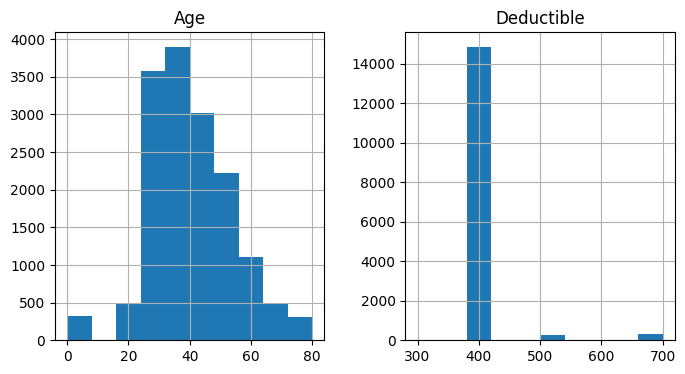

Age
0     320
16      9
17      6
18     48
19     32
     ... 
76     42
77     29
78     35
79     20
80     32
Name: count, Length: 66, dtype: int64
Deductible
300        8
400    14838
500      263
700      311
Name: count, dtype: int64


In [ ]:
#histograms of numerical variables
df[num_cols].hist(figsize=(8,4))
plt.show()
print(df['Age'].value_counts().sort_index())
print(df['Deductible'].value_counts().sort_index())

<div style="text-align: justify">

**Age:**
Age follows a right-skewed distribution rather than a perfectly normal one. The
highest concentration of policyholders falls between 30 and 45 years old, peaking around age 35 to 40. The count declines steadily after 40 and tapers off considerably beyond 60, with relatively few policyholders in the 65 to 80 range. Notably, the value_counts output shows 320 records at age 0, which appear as the first bar on the left of the histogram. These are clearly data entry errors or placeholder values and are not plausible ages for a vehicle insurance policyholder. Combined with a small number of records at ages 16 and 17, this confirms that an age filter removing values below 16 (and the erroneous 0 entries) is necessary before modelling proceeds.
*Update: after model evaluation, retaining these records was found to improve recall, suggesting that these cases may carry implicit signal related to fraudulent behavior (e.g., improperly filed or suspicious claims). Therefore, age = 0 values are retained as a separate category rather than removed.*

**Deductible:**
The Deductible histogram shows an extreme concentration at a single value. Of the 15,420 records, 14,838 (approximately 96%) have a deductible of 400, making it by far the dominant category. The remaining three values, 300 (8 records), 500 (263 records), and 700 (311 records), are marginally represented and barely visible in the histogram despite matplotlib rendering them as separate bars. This near-zero variance across the dataset means Deductible will contribute very limited discriminatory power as a standalone predictor. It is retained for modelling as it may contribute marginal signal in combination with other features, but its predictive usefulness should be interpreted cautiously given the severe class imbalance within the variable itself.

</div>

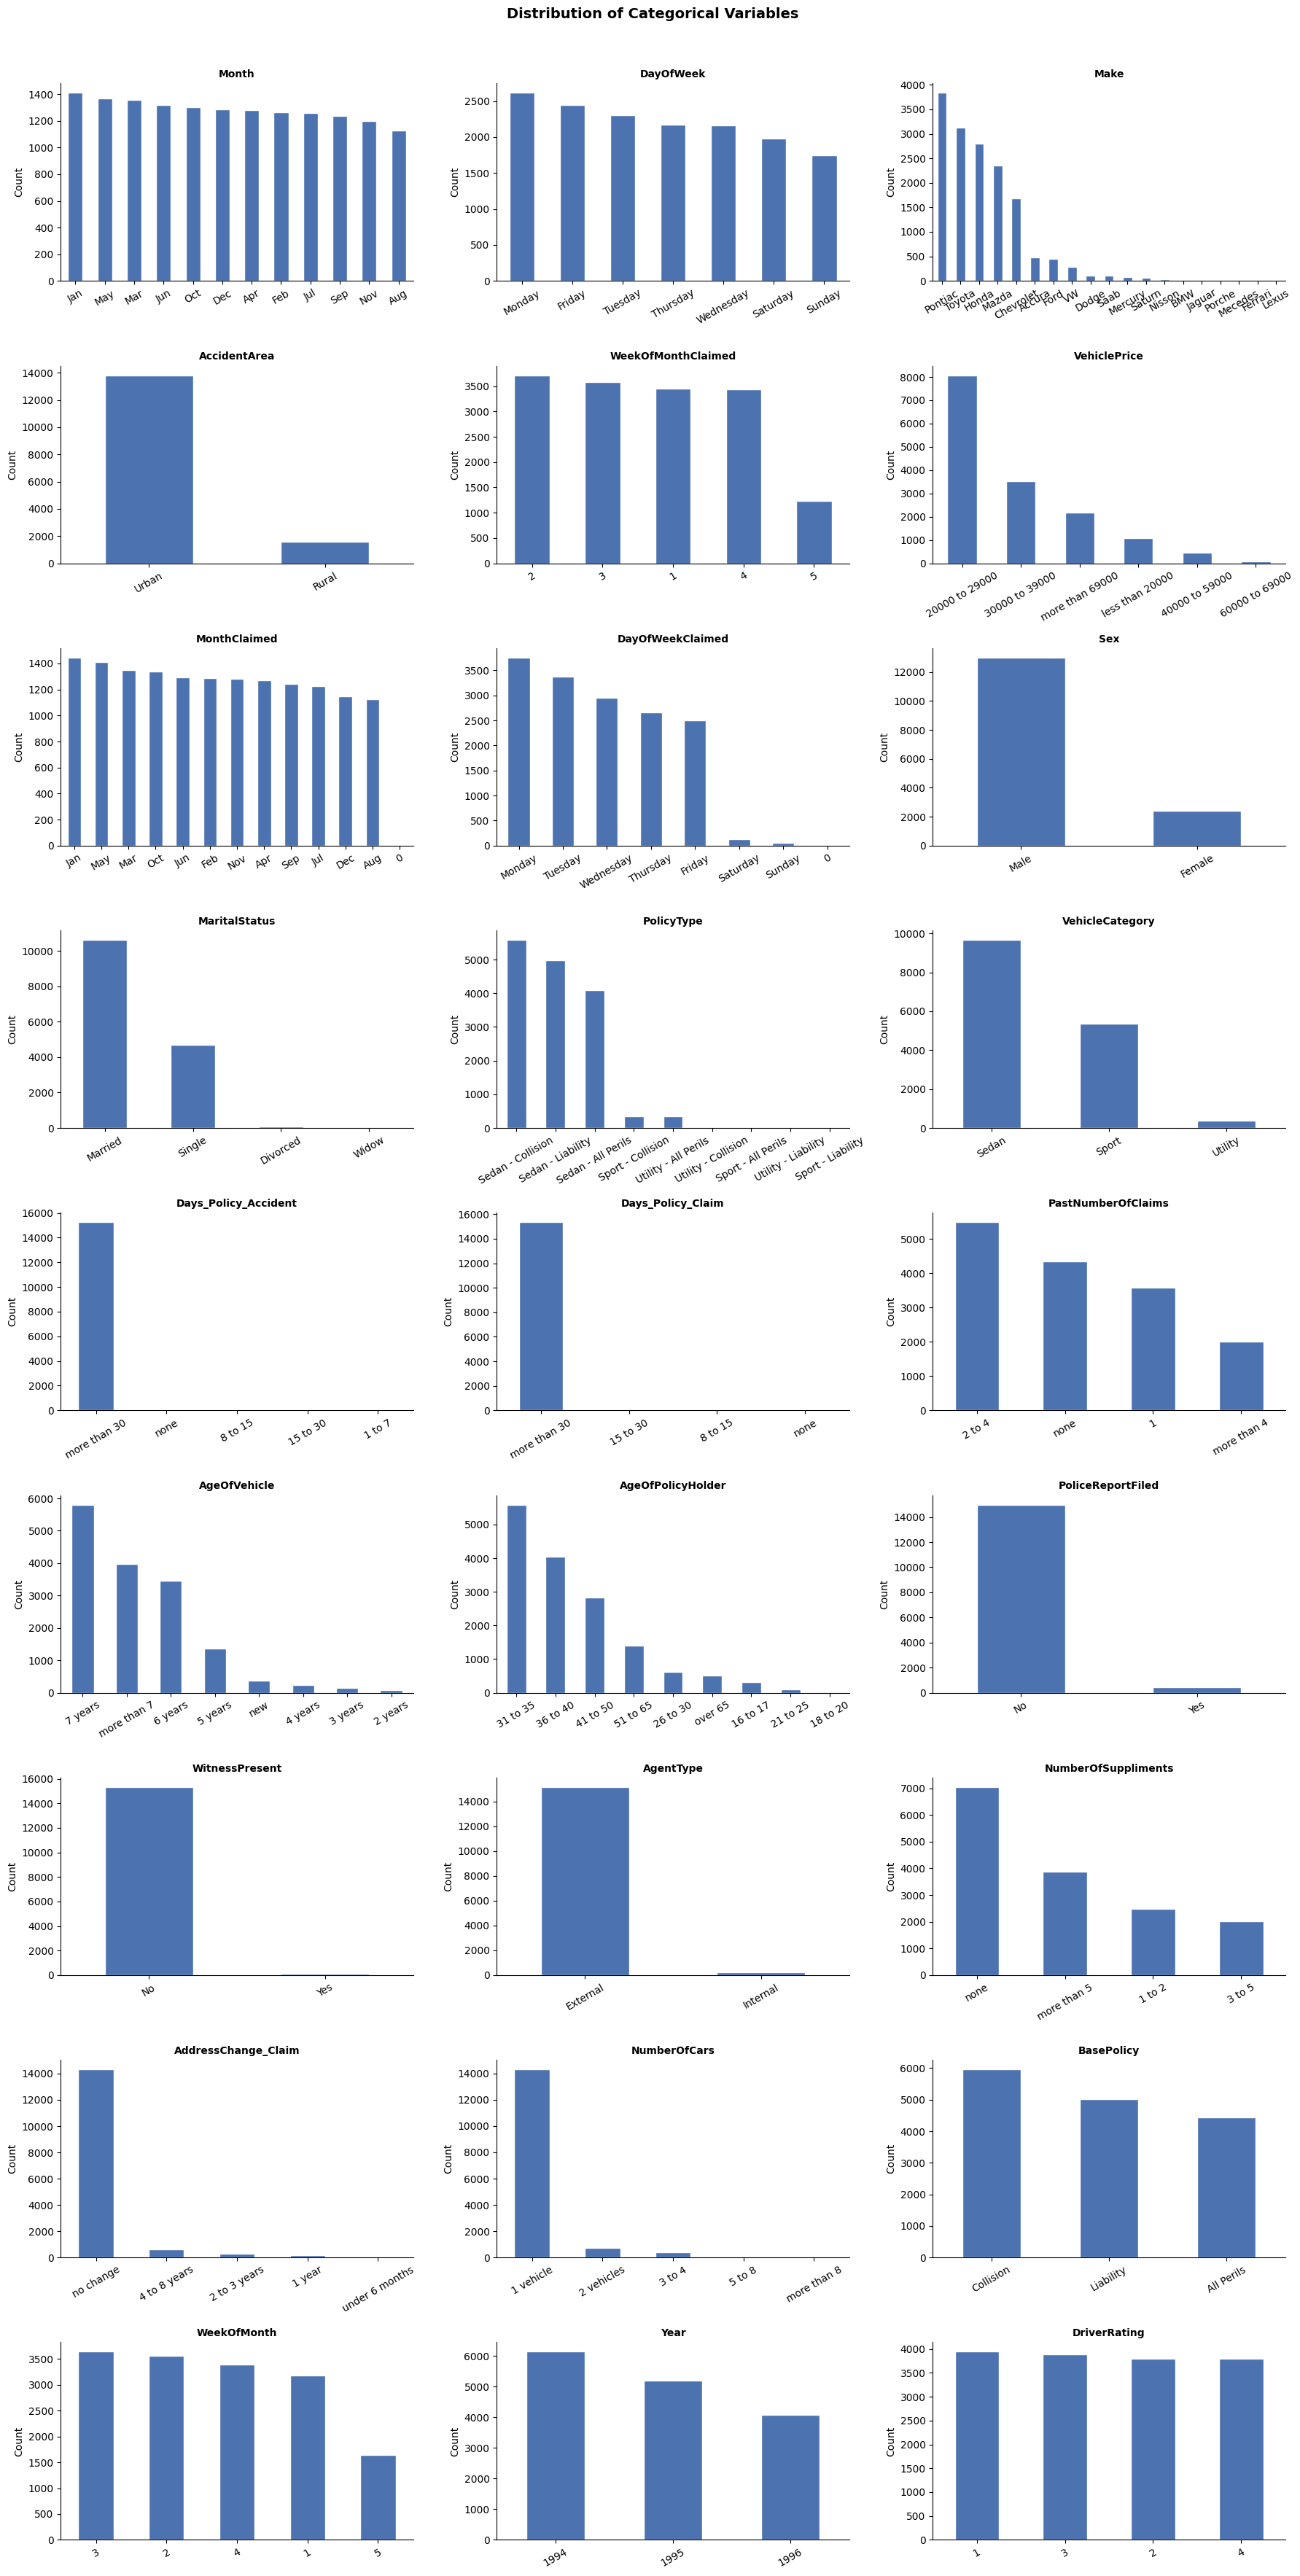

In [ ]:
#Bar charts of categorical variables

n_cols = 3
n_rows = math.ceil(len(cat_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    df[col].value_counts().plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="white")
    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

plt.suptitle("Distribution of Categorical Variables", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

The bar charts reveal the distribution of all 27 categorical variables. The key observations from each chart are as follows:

**Month and MonthClaimed** are both roughly uniformly distributed across all months, with January showing a slight peak. Claims appear to be filed at a broadly consistent rate throughout the year with no dramatic seasonal concentration. Note that both DayOfWeekClaimed and MonthClaimed contain a "0" category, which likely represents a data entry error or missing value and should be noted as a data quality issue.

**DayOfWeek and DayOfWeekClaimed** show that Monday is the most common day for both accidents and claims to be recorded, with Sunday being the least common. Weekend days show notably lower counts, which may reflect reduced reporting activity rather than fewer accidents.

**Make**  Pontiac is the most frequently represented vehicle make, followed by Honda, Dodge, and Toyota. Luxury and less common makes such as Porsche, Jaguar, and Lexus appear with very low frequency.

**AccidentArea** is heavily dominated by Urban accidents, which account for the vast majority of records. Rural accidents represent a small minority, consistent with higher traffic density in urban environments.

**VehiclePrice** shows that the most common price bracket is 20,000 to 29,000, followed by 30,000 to 39,000. Higher-priced vehicles above 60,000 are very rare in the dataset.

**Sex** shows a strong imbalance, with male policyholders substantially outnumbering females. This likely reflects the composition of the vehicle-owning population in the dataset rather than a fraud-specific pattern.

**MaritalStatus** is dominated by married policyholders, who represent roughly double the count of single policyholders. Divorced and widowed categories are negligibly small.

**PolicyType** shows Sedan Collision as the most common policy type, followed by Sedan Liability. All other policy types, including Sport and Utility variants, are comparatively rare.

**VehicleCategory** is dominated by Sedan, which accounts for the large majority of records. Sport vehicles represent the second category and Utility is very rarely represented.

**Days_Policy_Accident and Days_Policy_Claim** are both overwhelmingly dominated by the "more than 30" category, indicating that the vast majority of policyholders had their policy active for over a month before the accident and claim were recorded. Cases with very short gaps between policy activation and accident are rare, making the QuickClaim engineered feature a minority flag.

**PastNumberOfClaims** shows that the most common category is "2 to 4" prior claims, followed closely by "none" and then "1". This is a notable pattern: the majority of claimants in the dataset are not first-time claimants, suggesting a repeat-claim population.

**AgeOfVehicle** shows older vehicles are most prevalent, with "7 years" being the most common category, and counts declining as vehicles get newer. This means most insured vehicles in the dataset are relatively old.

**AgeOfPolicyHolder** peaks at the 31 to 35 and 36 to 40 age brackets, consistent with the Age histogram, and declines toward both younger and older brackets.

**PoliceReportFiled and WitnessPresent** are both overwhelmingly dominated by the "No" category, with the "Yes" category barely visible on the charts. This confirms that official documentation is almost never present for claims in this dataset, limiting these variables individually but making their presence a potentially strong signal when it does occur.

**AgentType** is dominated by External agents, with Internal agents representing a small fraction of cases.

**NumberOfSuppliments** shows that "none" is the most common value, but "more than 5" is the second most common category, which is unexpected. This suggests a bimodal pattern where policyholders either have no supplements at all or a very high number, with moderate counts being less common.

**AddressChange_Claim** is dominated by "no change", with all other categories, particularly recent changes under 6 months, being rare. This means the AddressChange feature will be a sparse but potentially high-signal flag for fraud cases where a recent change is observed.

**NumberOfCars** is almost entirely represented by "1 vehicle", with all other categories being negligibly small.

**BasePolicy** is the most balanced of all categorical variables, with Collision, Liability, and All Perils each representing roughly similar proportions of the dataset.

**Year** shows a declining pattern from 1994 to 1996, with 1994 being the most represented year. The dataset covers only three years.

**DriverRating** shows a relatively even distribution across all four rating values (1, 2, 3, 4), with rating 1 marginally most common. This makes DriverRating one of the more balanced categorical features in the dataset.

# 4. Handling Missing Values

In [ ]:
df.isnull().sum()

# No missing values were detected in the dataset.
# Therefore, no imputation or row deletion was required.

,0
Month,0
WeekOfMonth,0
DayOfWeek,0
Make,0
AccidentArea,0
DayOfWeekClaimed,0
MonthClaimed,0
WeekOfMonthClaimed,0
Sex,0
MaritalStatus,0


There are no missing values in the dataset.

# 5. Bivariate / Multivariate Exploration

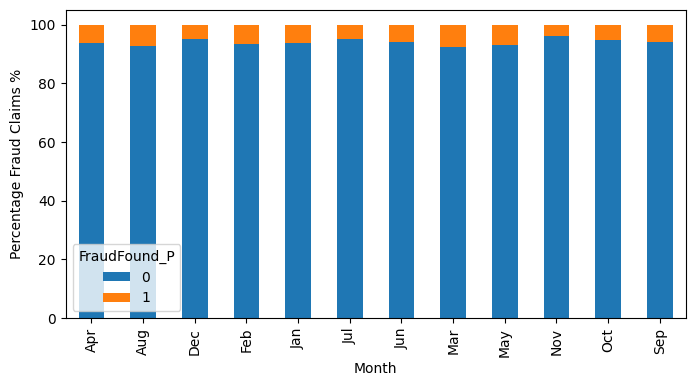

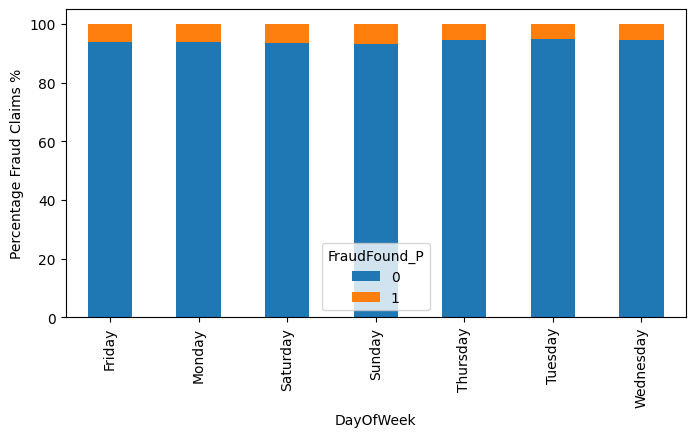

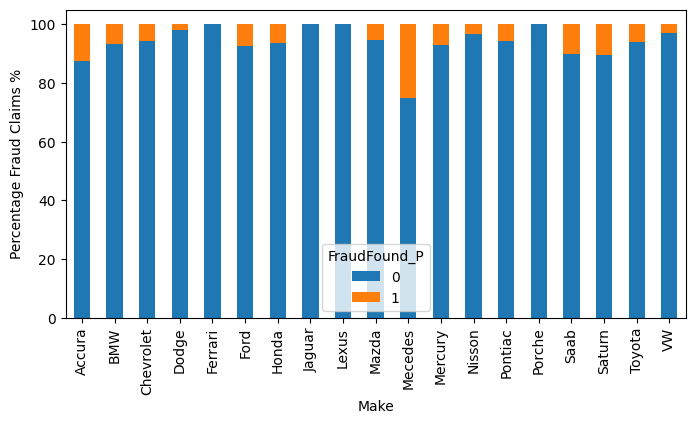

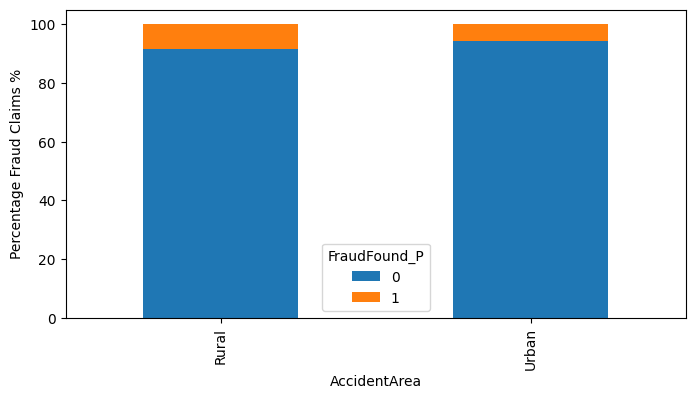

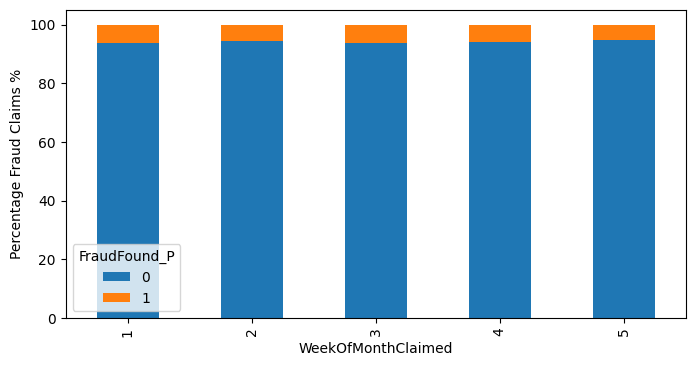

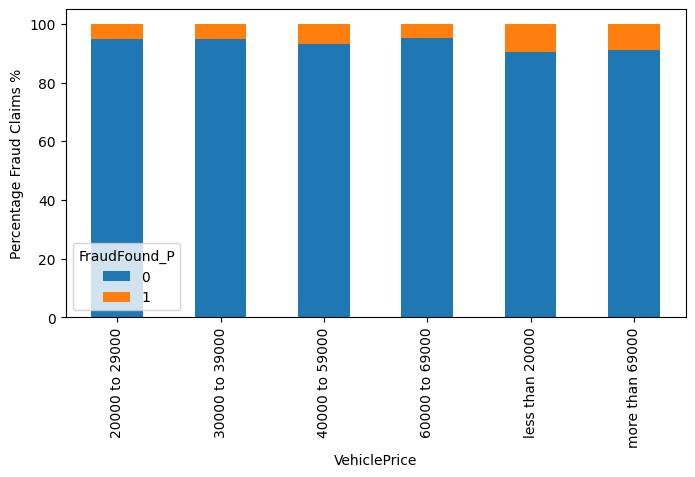

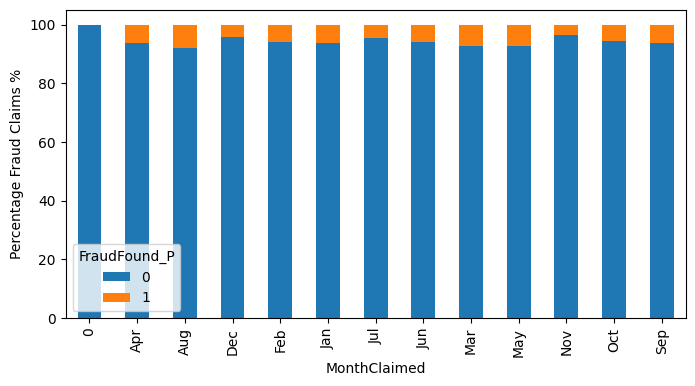

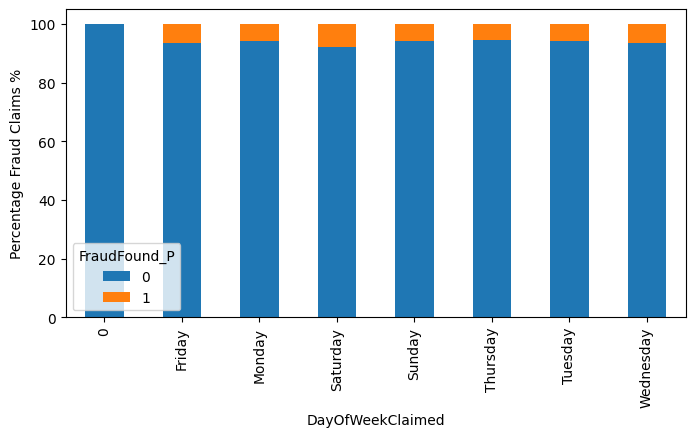

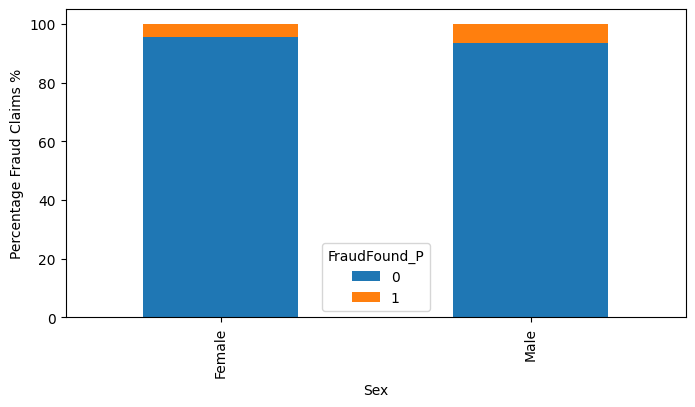

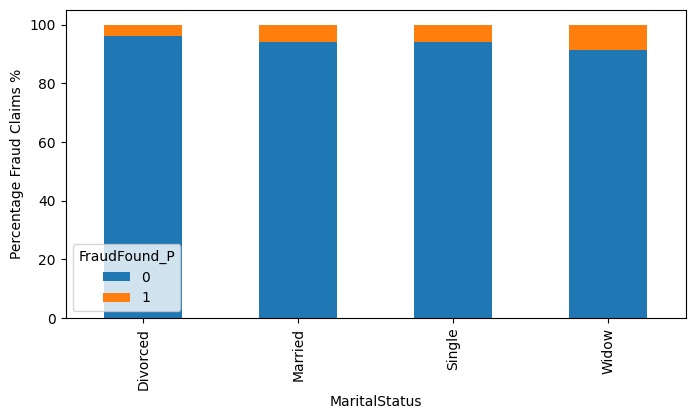

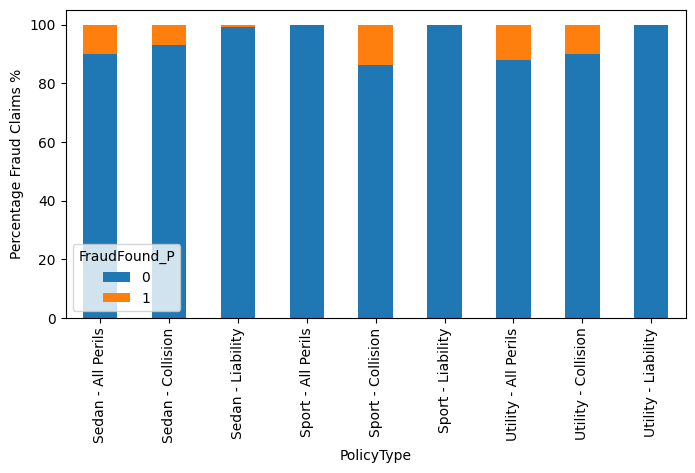

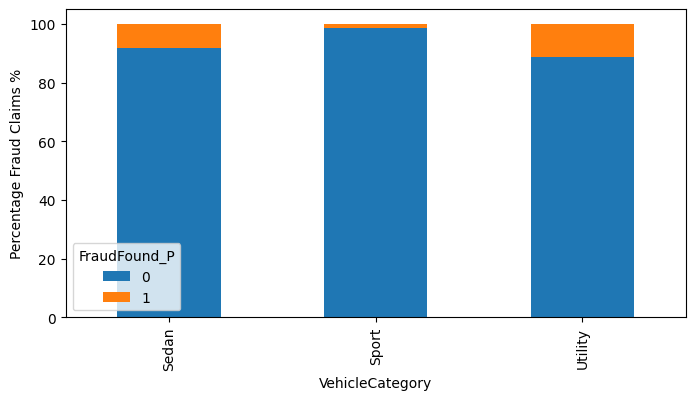

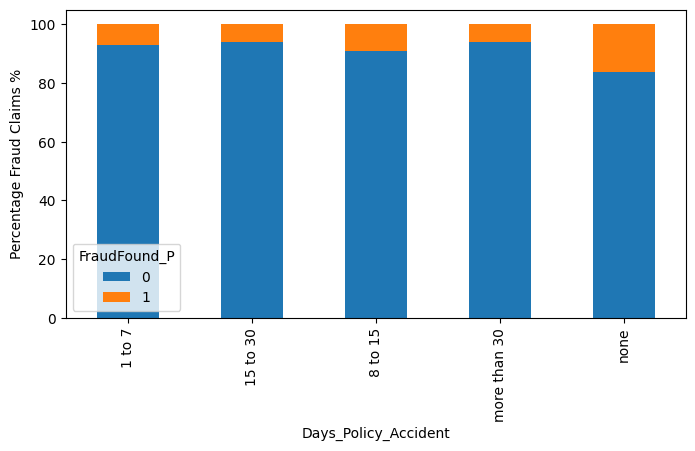

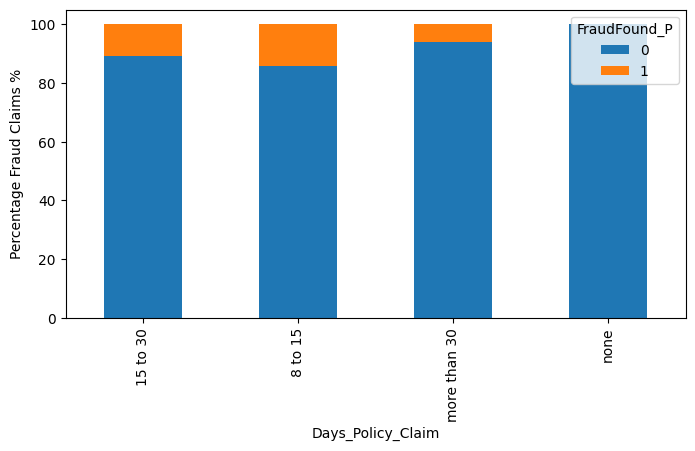

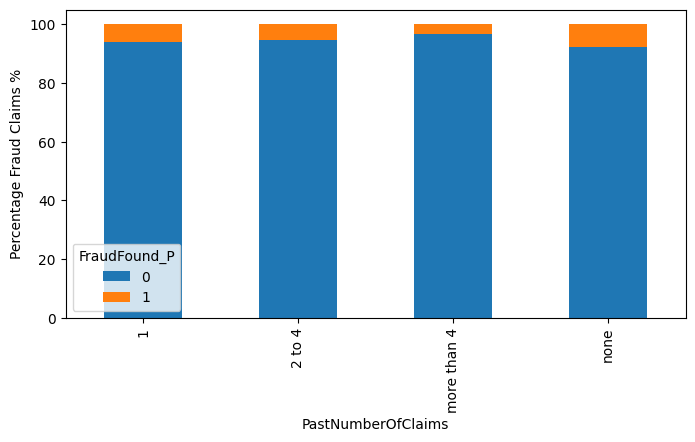

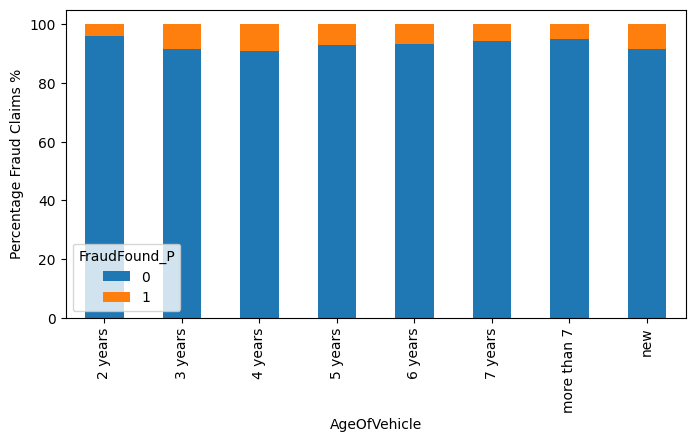

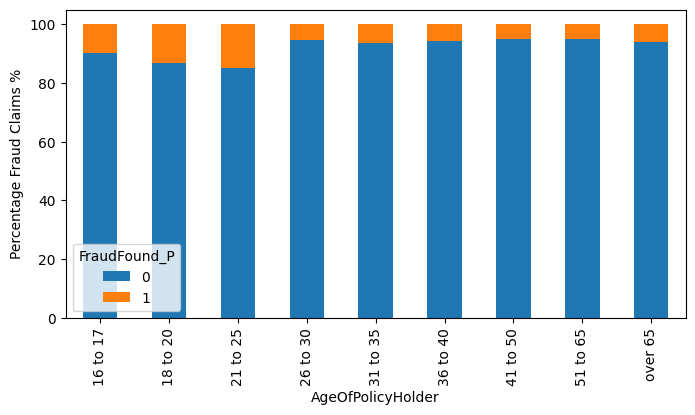

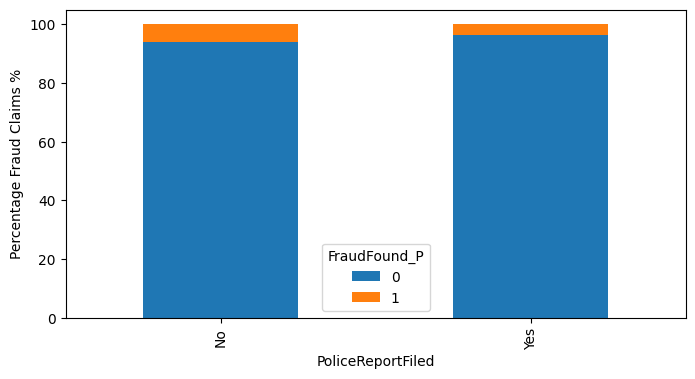

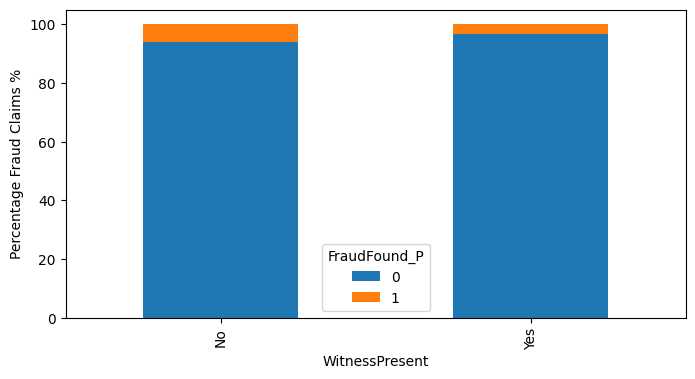

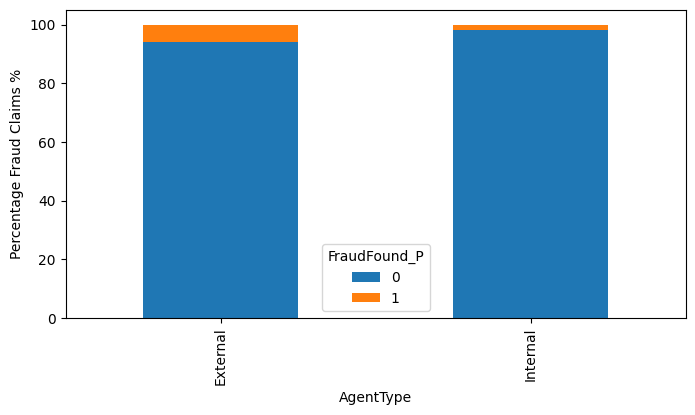

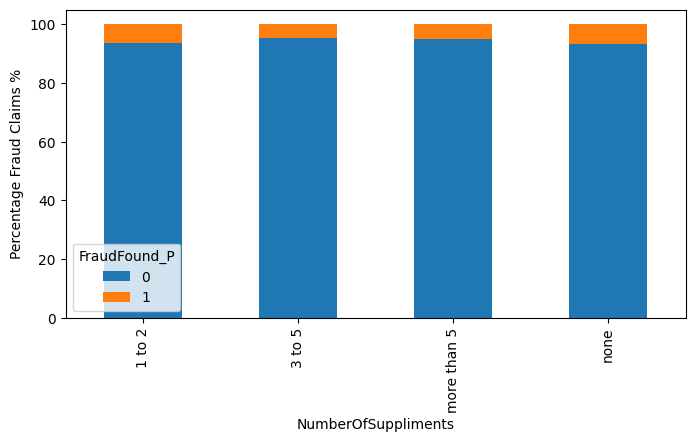

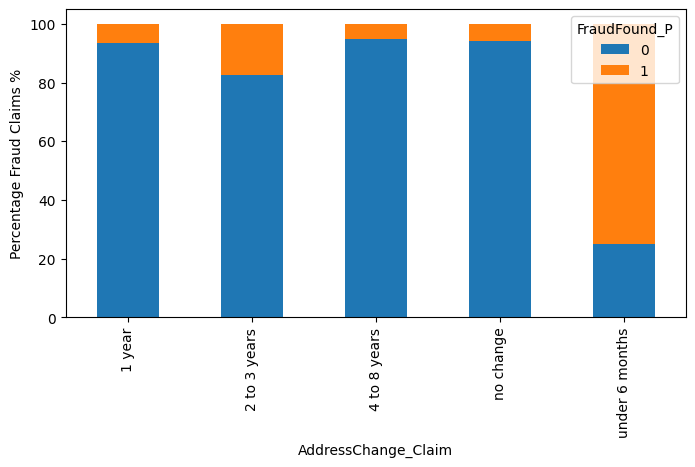

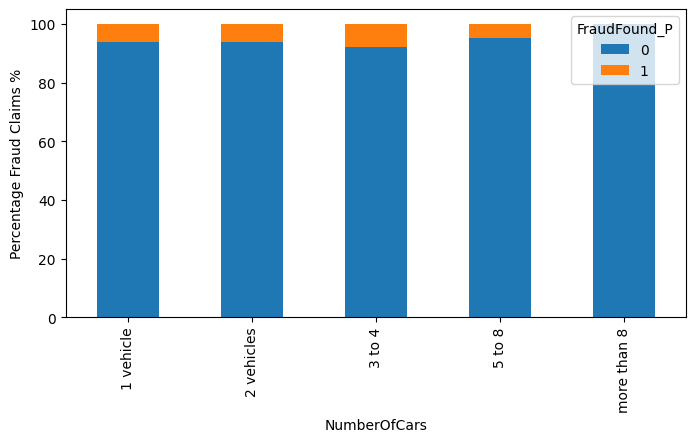

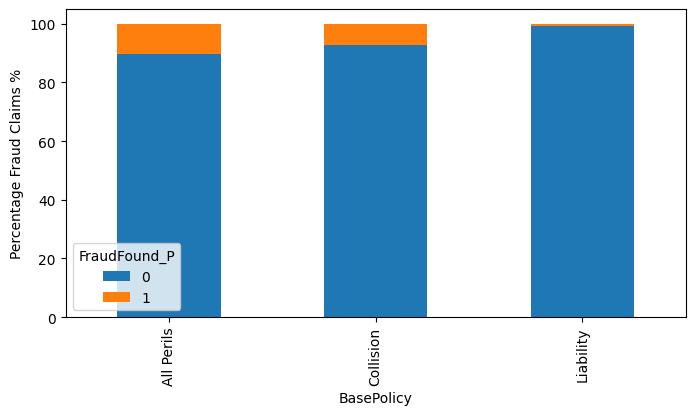

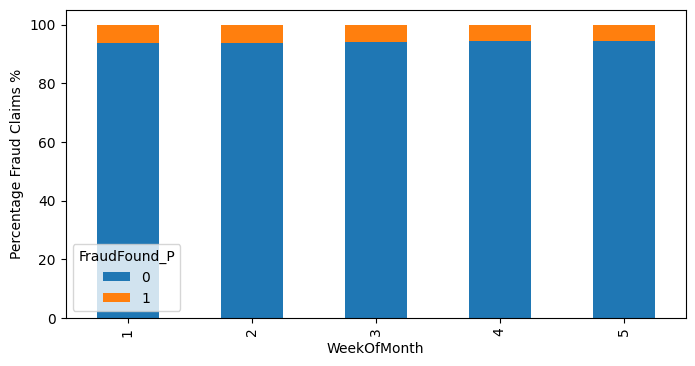

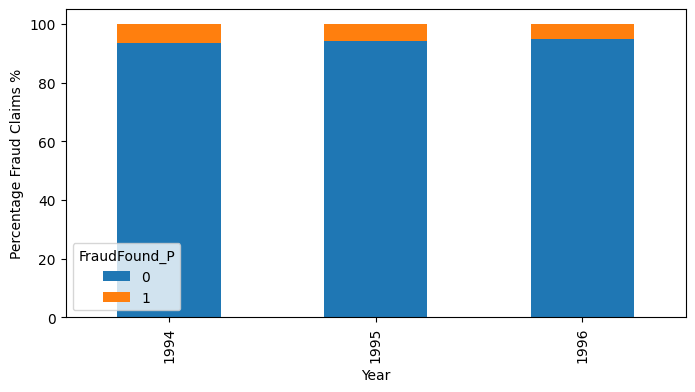

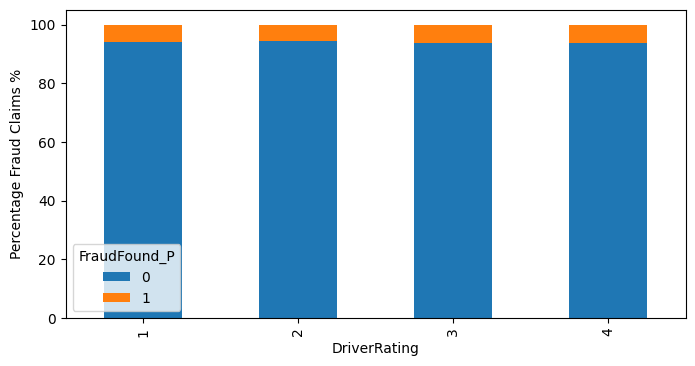

In [ ]:
#plots of categorical variables
for i in cat_cols:
    if i!='FraudFound_P':
        (pd.crosstab(df[i],df['FraudFound_P'],normalize='index')*100).plot(kind='bar',figsize=(8,4),stacked=True)
        plt.ylabel('Percentage Fraud Claims %')

Here, each bar represents the proportion of fraudulent (orange) versus legitimate (maroon) claims within every category of a given variable. This is the most informative section of the exploratory analysis because it directly shows which feature values are associated with higher fraud rates.

We plotted categorical variables against the percentage of fraudulent claims where "fraud found" was measured for each variable. This allowed us to analyze the distribution of fraudulent (1) vs non-fraudulent (0) claims for each variable.
Across all charts, the overall fraud rate sits at approximately 6%, meaning the orange segment is consistently small. There appear to not be that many fraudulent cases in the dataset, suggesting class imbalance.

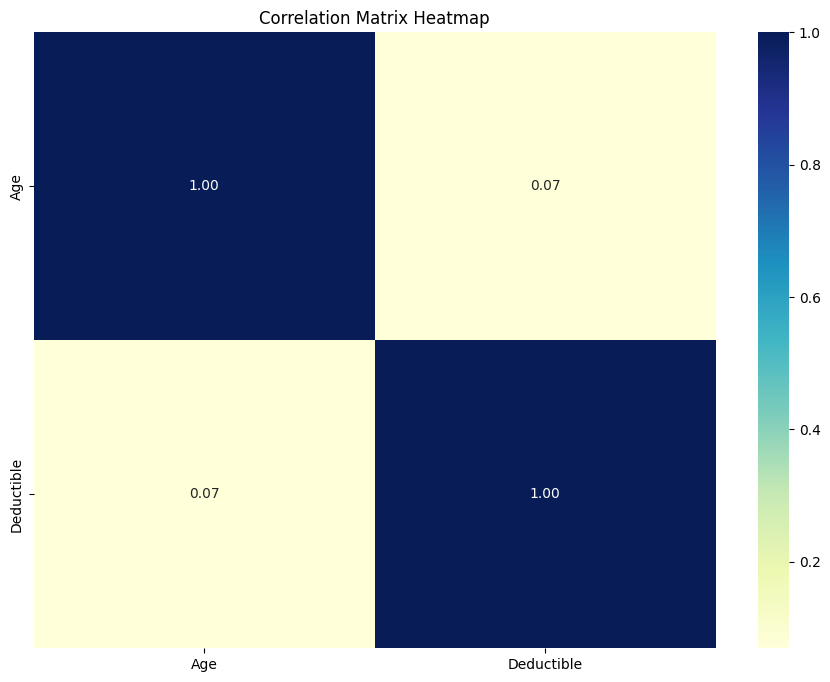

In [ ]:
#Heatmap of numerical values
plt.figure(figsize=(11,8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='0.2f', cmap='YlGnBu')
plt.title("Correlation Matrix Heatmap")
plt.show()

The correlation heatmap displays the pairwise correlation between the two numerical variables in the dataset, Age and Deductible. Each variable correlates perfectly with itself along the diagonal (r = 1.00), as expected. The off-diagonal value of r = 0.07 indicates a negligible linear relationship between Age and Deductible, meaning the two variables are effectively independent of one another. There is no multicollinearity concern between these features, and each contributes a distinct dimension of information to the model.

Technically, there are no numerical variables that are strongly correlated with one another.

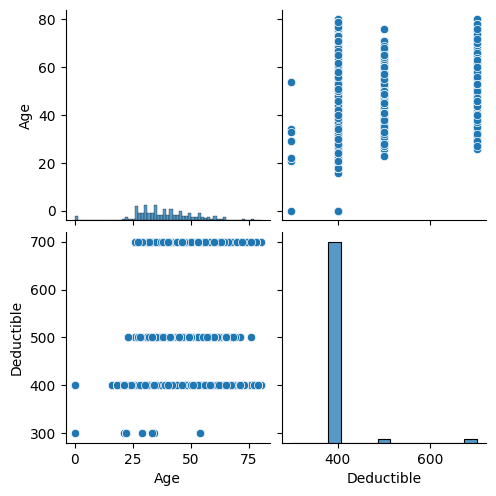

In [ ]:
# Pairplot for Numerical Variables
sns.pairplot(df[num_cols])
plt.show()

The pairplot displays the relationship between the two numerical variables, Age and Deductible, with scatter plots on the off-diagonal and histograms on the diagonal. The scatter plot confirms there is no meaningful linear or monotonic relationship between Age and Deductible. Points are spread across all combinations of the four deductible values without any systematic pattern tied to age, reinforcing the near-zero correlation (r = 0.07) identified in the heatmap. The horizontal banding in the scatter plot is a direct consequence of Deductible being a discrete variable with only four possible values (300, 400, 500, 700), producing four distinct rows of points rather than a continuous cloud. The Age histogram on the diagonal reveals the right-skewed age distribution discussed in Section 3, and notably shows a concentration of records at age 0, confirming the data quality issue identified earlier that will be addressed through filtering in Section 6. The Deductible histogram confirms the extreme concentration at the value 400, with the other three values barely visible by comparison.

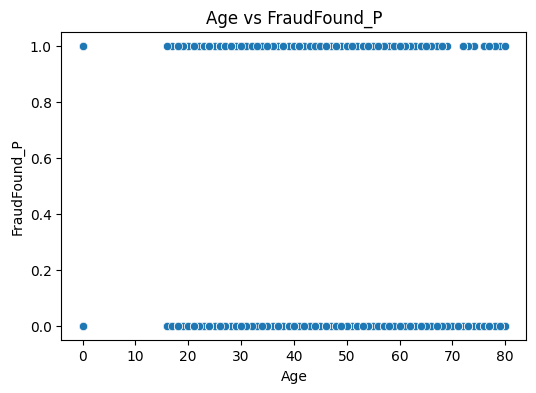

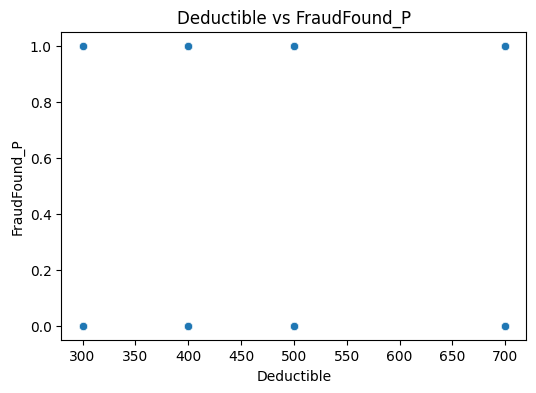

In [ ]:
# Scatterplots vs Target
target_column = "FraudFound_P"

for col in num_cols:
    if col != target_column:
        plt.figure(figsize=(6,4))
        sns.scatterplot(x=df[col], y=df[target_column])
        plt.title(f"{col} vs {target_column}")
        plt.show()

The scatterplot of Age against FraudFound_P illustrates why scatterplots are a limited tool when the target variable is binary. FraudFound_P can only take two values, 0 or 1, so all data points collapse into two horizontal bands regardless of the feature being plotted. Both fraud cases (value 1, top band) and legitimate cases (value 0, bottom band) are distributed across the full age range from 16 to 80, with no visible age threshold or concentration that separates the two classes. This confirms that Age alone is not a sufficient predictor of fraud. The same pattern holds for Deductible, where the four discrete values produce a grid-like scatter with no separation between the two target classes. Notably, the cluster of points at age 0 in both bands is visible here again, confirming the data quality issue flagged in Section 3 that will be removed by the age filter in Section 6. The scatterplot format is retained here for completeness, but the stacked bar charts in Section 5 are a more appropriate visualisation for understanding how numerical and categorical variables relate to a binary target.

# 6. Outlier Detection and Handling

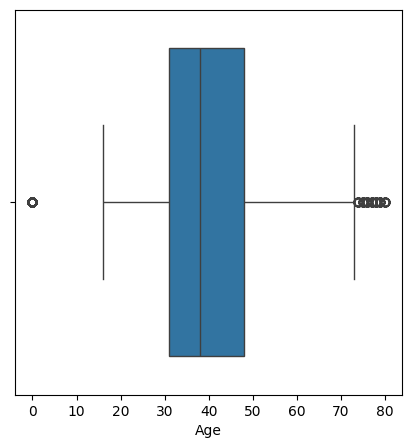

In [ ]:
plt.figure(figsize=(5,5))
sns.boxplot(x=df['Age'])
plt.show()

The boxplot shows that the middle 50% of policyholders (the interquartile range) fall between approximately 30 and 48 years old, with the median sitting at around 38 to 40 years. The whiskers extend to roughly 16 on the lower end and 72 on the upper end, representing the range of non-outlier values. On the right side of the plot, a small cluster of outliers is visible beyond the upper whisker, corresponding to policyholders aged 75 and above. On the far left, a single isolated outlier is visible at or near age 0, which is clearly a data entry error and not a plausible age for a vehicle insurance policyholder. There are no additional low-value outliers between 0 and 16, meaning the sub-16 issue is confined to this single erroneous zero entry and a small number of records in the 16 to 18 range visible in the value_counts output from Section 3. The age 0 records and any records below the legal driving age of 16 will be removed before modelling proceeds, as they represent either data entry errors or values that are not plausible for a licensed driver.






In [ ]:
# Removing ages less than 16
df = df[df['Age'] >= 16]

df[['Age']].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,15100.0,40.700331,12.309493,16.0,31.0,39.0,49.0,80.0


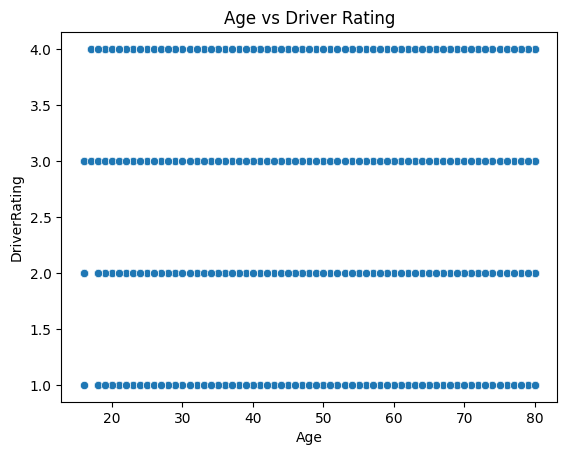

In [ ]:
sns.scatterplot(x='Age', y='DriverRating', data=df)
plt.title('Age vs Driver Rating')
plt.show()

The scatterplot of Age against DriverRating confirms that the age filter applied in the previous step has worked correctly, with the x-axis now starting at approximately 16 and no age 0 records remaining. All four driver rating values (1, 2, 3, 4) are present across the full age range from 16 to 80, producing four perfectly horizontal bands of points with no slope or curvature. This pattern confirms there is no linear, monotonic, or any other systematic relationship between a policyholder's age and their driver rating in this dataset. Younger drivers are no more likely to hold a low rating than older drivers, and vice versa. The equal density of points across all age groups within each rating band further suggests that driver ratings are distributed roughly uniformly across ages. The two variables are independent of one another and can both be retained in the model without one acting as a proxy for the other. DriverRating will be treated as an ordinal categorical variable given its four discrete integer values, while Age is retained as a continuous numerical feature.



# 7. Categorical Encoding

In [ ]:
# ── Step 1: Binary encoding (two-category columns → 0/1) ─────────────────────
df['PoliceReportFiled'] = df['PoliceReportFiled'].map({'Yes': 1, 'No': 0})
df['WitnessPresent']    = df['WitnessPresent'].map({'Yes': 1, 'No': 0})
df['Sex']               = df['Sex'].map({'Male': 1, 'Female': 0})
df['AccidentArea']      = df['AccidentArea'].map({'Urban': 1, 'Rural': 0})
df['Fault']             = df['Fault'].map({'Policy Holder': 1, 'Third Party': 0})
df['AgentType']         = df['AgentType'].map({'External': 0, 'Internal': 1})

print("Binary encoding complete.")
print(df[['PoliceReportFiled','WitnessPresent','Sex',
          'AccidentArea','Fault','AgentType']].head(3))

# ── Step 2: Ordinal encoding (ranked categories → ordered integers) ───────────
vehicle_price_map = {
    'less than 20000': 1, '20000 to 29000': 2,
    '30000 to 39000': 3,  '40000 to 59000': 4,
    '60000 to 69000': 5,  'more than 69000': 6
}
age_of_vehicle_map = {
    'new': 1,     '2 years': 2, '3 years': 3, '4 years': 4,
    '5 years': 5, '6 years': 6, '7 years': 7, 'more than 7': 8
}
age_of_policyholder_map = {
    '16 to 17': 1, '18 to 20': 2, '21 to 25': 3,
    '26 to 30': 4, '31 to 35': 5, '36 to 40': 6,
    '41 to 50': 7, '51 to 65': 8, 'over 65':  9
}
days_policy_accident_map = {
    'none': 0, '1 to 7': 1, '8 to 15': 2,
    '15 to 30': 3, 'more than 30': 4
}
days_policy_claim_map = {
    'none': 0, '8 to 15': 1, '15 to 30': 2, 'more than 30': 3
}
past_claims_map = {
    'none': 0, '1': 1, '2 to 4': 2, 'more than 4': 3
}
num_suppliments_map = {
    'none': 0, '1 to 2': 1, '3 to 5': 2, 'more than 5': 3
}
address_change_map = {
    'no change': 0,    '1 year': 1,      '2 to 3 years': 2,
    '4 to 8 years': 3, 'under 6 months': 4
}
number_of_cars_map = {
    '1 vehicle': 1, '2 vehicles': 2, '3 to 4': 3,
    '5 to 8': 4,    'more than 8': 5
}

df['VehiclePrice']         = df['VehiclePrice'].map(vehicle_price_map)
df['AgeOfVehicle']         = df['AgeOfVehicle'].map(age_of_vehicle_map)
df['AgeOfPolicyHolder']    = df['AgeOfPolicyHolder'].map(age_of_policyholder_map)
df['Days_Policy_Accident'] = df['Days_Policy_Accident'].map(days_policy_accident_map)
df['Days_Policy_Claim']    = df['Days_Policy_Claim'].map(days_policy_claim_map)
df['PastNumberOfClaims']   = df['PastNumberOfClaims'].map(past_claims_map)
df['NumberOfSuppliments']  = df['NumberOfSuppliments'].map(num_suppliments_map)
df['AddressChange_Claim']  = df['AddressChange_Claim'].map(address_change_map)
df['NumberOfCars']         = df['NumberOfCars'].map(number_of_cars_map)

print("\nOrdinal encoding complete.")
print(df[['VehiclePrice','AgeOfVehicle','AgeOfPolicyHolder',
          'Days_Policy_Accident','Days_Policy_Claim',
          'PastNumberOfClaims','NumberOfSuppliments',
          'AddressChange_Claim','NumberOfCars']].head(3))

Binary encoding complete.
   PoliceReportFiled  WitnessPresent  Sex  AccidentArea  Fault  AgentType
0                  0               0    0             1      1          0
1                  1               0    1             1      1          0
2                  0               0    1             1      1          0

Ordinal encoding complete.
   VehiclePrice  AgeOfVehicle  AgeOfPolicyHolder  Days_Policy_Accident  \
0             6             3                  4                     4   
1             6             6                  5                     4   
2             6             7                  7                     4   

   Days_Policy_Claim  PastNumberOfClaims  NumberOfSuppliments  \
0                  3                   0                    0   
1                  3                   0                    0   
2                  3                   1                    0   

   AddressChange_Claim  NumberOfCars  
0                    1             3  
1             

In [ ]:
# ── Step 3: One-hot encode remaining nominal columns ─────────────────────────
# Only columns with no natural order and more than 2 categories
# FraudFound_P is intentionally excluded — it is the integer target column
# WeekOfMonth, WeekOfMonthClaimed, Year are already integers — no encoding needed

nominal_cols = [
    'Month', 'DayOfWeek', 'Make', 'DayOfWeekClaimed',
    'MonthClaimed', 'MaritalStatus', 'PolicyType',
    'VehicleCategory', 'BasePolicy'
]

df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)

print("One-hot encoding complete.")
print(f"\nShape after full encoding: {df.shape}")
print(f"\nFraudFound_P still intact : {'FraudFound_P' in df.columns}")
print(f"FraudFound_P dtype        : {df['FraudFound_P'].dtype}")
print(f"FraudFound_P value counts :\n{df['FraudFound_P'].value_counts()}")

One-hot encoding complete.

Shape after full encoding: (15100, 89)

FraudFound_P still intact : True
FraudFound_P dtype        : int64
FraudFound_P value counts :
FraudFound_P
0    14208
1      892
Name: count, dtype: int64


# 8. Feature Engineering

In [ ]:
# ── Feature Engineering ───────────────────────────────────────────────────────
# All columns below are now clean ordinal integers after Section 7 encoding

# 1. Old vehicle + high supplements = suspicious combination
#    AgeOfVehicle 7-8 = oldest vehicles, NumberOfSuppliments 2-3 = most supplements
df['OldVehicle_HighSuppliments'] = (
    (df['AgeOfVehicle'] >= 7).astype(int) *
    (df['NumberOfSuppliments'] >= 2).astype(int)
)

# 2. Young driver + no police report = suspicious
#    AgeOfPolicyHolder 1-2 = youngest brackets (16-17, 18-20)
#    PoliceReportFiled = 0 means no report filed
df['Young_NoPoliceReport'] = (
    (df['AgeOfPolicyHolder'] <= 2).astype(int) *
    (1 - df['PoliceReportFiled'])
)

# 3. Claim filed very soon after policy start = suspicious
#    Days_Policy_Accident 0 or 1 = none or within 7 days of policy start
df['QuickClaim_Flag'] = (
    (df['Days_Policy_Accident'] <= 1).astype(int)
)

# ── Preview ───────────────────────────────────────────────────────────────────
new_feats = ['OldVehicle_HighSuppliments', 'Young_NoPoliceReport', 'QuickClaim_Flag']
print("New features created:")
print(df[new_feats].describe())

print(f"\nFraud rate — OldVehicle_HighSuppliments = 1 : "
      f"{df[df['OldVehicle_HighSuppliments']==1]['FraudFound_P'].mean()*100:.1f}%")
print(f"Fraud rate — Young_NoPoliceReport = 1        : "
      f"{df[df['Young_NoPoliceReport']==1]['FraudFound_P'].mean()*100:.1f}%")
print(f"Fraud rate — QuickClaim_Flag = 1             : "
      f"{df[df['QuickClaim_Flag']==1]['FraudFound_P'].mean()*100:.1f}%")

print(f"\nDataframe shape after feature engineering: {df.shape}")

New features created:
       OldVehicle_HighSuppliments  Young_NoPoliceReport  QuickClaim_Flag
count                15100.000000          15100.000000     15100.000000
mean                     0.273377              0.000993         0.004570
std                      0.445708              0.031503         0.067446
min                      0.000000              0.000000         0.000000
25%                      0.000000              0.000000         0.000000
50%                      0.000000              0.000000         0.000000
75%                      1.000000              0.000000         0.000000
max                      1.000000              1.000000         1.000000

Fraud rate — OldVehicle_HighSuppliments = 1 : 4.5%
Fraud rate — Young_NoPoliceReport = 1        : 13.3%
Fraud rate — QuickClaim_Flag = 1             : 14.5%

Dataframe shape after feature engineering: (15100, 92)


# 9. Feature Selection / Removal

Dropped: AgeOfPolicyHolder (r=0.972 with Age)
Dropped: QuickClaim_Flag (r=0.883 with Days_Policy_Accident)


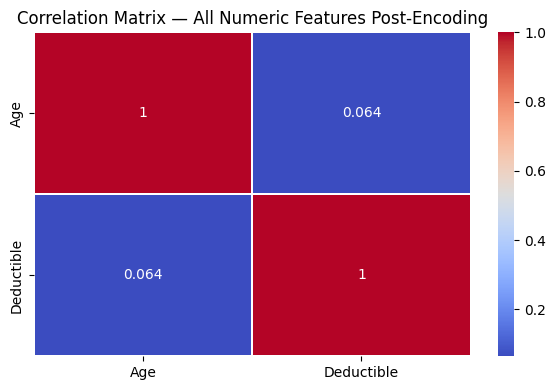


No remaining feature pairs exceed 0.85 — no further removals needed.

FraudFound_P intact : True
dtype               : int64
Value counts        :
FraudFound_P
0    14208
1      892
Name: count, dtype: int64

Final shape: (15100, 90)


In [ ]:
# ── Step 1: Drop highly correlated features identified above ─────────────────

# AgeOfPolicyHolder vs Age: r = 0.972
# Keep Age (raw continuous integer), drop AgeOfPolicyHolder (ordinal proxy)
if 'AgeOfPolicyHolder' in df.columns:
    df.drop(columns=['AgeOfPolicyHolder'], inplace=True)
    print("Dropped: AgeOfPolicyHolder (r=0.972 with Age)")

# QuickClaim_Flag vs Days_Policy_Accident: r = 0.883
# Keep Days_Policy_Accident (more informative ordinal), drop binary flag
if 'QuickClaim_Flag' in df.columns:
    df.drop(columns=['QuickClaim_Flag'], inplace=True)
    print("Dropped: QuickClaim_Flag (r=0.883 with Days_Policy_Accident)")

# ── Step 2: Correlation heatmap on numeric features ──────────────────────────
# Select only required columns
subset_df = df[['Age', 'Deductible']]

# Compute correlation matrix
corr_matrix = subset_df.corr().abs()

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=True, linewidths=0.3)
plt.title('Correlation Matrix — All Numeric Features Post-Encoding')
plt.tight_layout()
plt.show()

# ── Step 3: Confirm no remaining pairs above 0.85 ────────────────────────────
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
high_corr_pairs = [
    (col, row, round(upper_tri.loc[row, col], 3))
    for col in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, col] > 0.85
]

if high_corr_pairs:
    print("\nStill highly correlated (>0.85):")
    for a, b, r in high_corr_pairs:
        print(f"  {a}  <-->  {b}  |  r = {r}")
else:
    print("\nNo remaining feature pairs exceed 0.85 — no further removals needed.")

# ── Step 4: Confirm target is intact ─────────────────────────────────────────
print(f"\nFraudFound_P intact : {'FraudFound_P' in df.columns}")
print(f"dtype               : {df['FraudFound_P'].dtype}")
print(f"Value counts        :\n{df['FraudFound_P'].value_counts()}")
print(f"\nFinal shape: {df.shape}")

Prior to plotting this heatmap, two highly correlated features were removed: AgeOfPolicyHolder was dropped due to its near-perfect correlation with Age (r = 0.972), and QuickClaim_Flag was dropped due to its strong correlation with Days_Policy_Accident (r = 0.883). Retaining both members of a highly correlated pair would introduce multicollinearity, which can destabilise coefficient estimates in linear models and inflate feature importance in tree-based models. The heatmap confirms that the two remaining continuous numeric features, Age and Deductible, have a correlation of just r = 0.064, indicating they are effectively independent of one another. The coolwarm colour scale makes this immediately visible: the diagonal self-correlations appear in deep red (r = 1.0) while the off-diagonal cells appear in deep blue, representing values close to zero. It should be noted that while the title states "All Numeric Features Post-Encoding", the heatmap currently only includes Age and Deductible. The ordinal-encoded features such as VehiclePrice, Days_Policy_Accident, and AddressChange_Claim are not included in this matrix. A more comprehensive correlation check across all encoded numeric features would provide a stronger guarantee that no residual multicollinearity remains in the full feature set.


# 10. Train-test split

In [ ]:
cols_to_scale = num_cols
cols_to_scale = [c for c in cols_to_scale if c in df.columns]
print(f"Columns to scale: {cols_to_scale}")

X = df.drop(columns=['FraudFound_P'])
y = df['FraudFound_P']

print(f"Feature matrix shape : {X.shape}")
print(f"Target vector shape  : {y.shape}")
print(f"Fraud rate           : {y.mean()*100:.2f}%")

# stratify=y ensures both splits preserve the fraud/non-fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Columns to scale: ['Age', 'Deductible']
Feature matrix shape : (15100, 89)
Target vector shape  : (15100,)
Fraud rate           : 5.91%


# 11. Scaling / Normalization

In [ ]:
# ── Apply StandardScaler AFTER the split to prevent data leakage ─────────────
# Fit only on training data, then apply the fitted scaler to the test set
scaler = StandardScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("\nScaling complete.")
print(X_train[cols_to_scale].describe().round(4))

print(f"\nTraining set   : {X_train.shape[0]} rows")
print(f"Test set       : {X_test.shape[0]} rows")
print(f"\nTrain fraud %  : {y_train.mean()*100:.2f}%")
print(f"Test  fraud %  : {y_test.mean()*100:.2f}%")

print(f"\nX_train dtypes (unique) : {X_train.dtypes.unique()}")
print(f"Any NaNs in X_train     : {X_train.isnull().sum().sum()}")
print(f"Any NaNs in X_test      : {X_test.isnull().sum().sum()}")
print("\nData is ready for modelling.")


Scaling complete.
              Age  Deductible
count  12080.0000  12080.0000
mean       0.0000      0.0000
std        1.0000      1.0000
min       -2.0091     -2.3806
25%       -0.7919     -0.1812
50%       -0.1427     -0.1812
75%        0.6688     -0.1812
max        3.1844      6.4173

Training set   : 12080 rows
Test set       : 3020 rows

Train fraud %  : 5.91%
Test  fraud %  : 5.89%

X_train dtypes (unique) : [dtype('int64') dtype('float64') dtype('bool')]
Any NaNs in X_train     : 0
Any NaNs in X_test      : 0

Data is ready for modelling.


In [ ]:
# Check which columns still have NaNs
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

Series([], dtype: int64)


In [ ]:
print(X_train.dtypes[X_train.dtypes == 'object'])

Series([], dtype: object)


# 12. SMOTE sampling for handling class imbalance

In [ ]:
# Apply SMOTE only to the training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Original training set shape:", X_train.shape, y_train.shape)
print("Resampled training set shape:", X_train_resampled.shape, y_train_resampled.shape)
print("Test set shape (unchanged):", X_test.shape, y_test.shape)

# Checking the counts
counts = pd.Series(y_train_resampled).value_counts().sort_index()
ratios = counts / counts.sum()

# Combine into one table
summary = pd.DataFrame({
    'Count': counts,
    'Ratio': ratios
})
print()
print(summary)

Original training set shape: (12080, 89) (12080,)
Resampled training set shape: (22732, 89) (22732,)
Test set shape (unchanged): (3020, 89) (3020,)

              Count  Ratio
FraudFound_P              
0             11366    0.5
1             11366    0.5


SMOTE was applied exclusively to the training data after the train-test split, which is the correct procedure for preventing data leakage. Applying SMOTE before splitting would allow synthetic minority samples derived from test set observations to enter the training data, artificially inflating model performance on the test set. The original training set contained 12,080 samples, which increased to 22,732 after resampling, an addition of 10,652 synthetic fraud cases generated by interpolating between existing minority class examples in feature space. The resulting class distribution is perfectly balanced, with both fraud and non-fraud classes each represented by exactly 11,366 samples at a 50-50 ratio. The test set remains entirely unchanged at 3,020 samples, preserving the original real-world class imbalance of approximately 94% non-fraud and 6% fraud. This ensures that model evaluation on the test set reflects genuine performance on the true distribution rather than an artificially balanced one. The balanced training data is expected to improve the model's ability to learn fraud patterns, particularly recall for the minority class, which is the primary metric of interest in this analysis.


# Creating the Metric Function

In [ ]:
#creating metric function
def metrics_score(actual, predicted):
    print(classification_report(actual, predicted))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(8,5))
    sns.heatmap(cm, annot=True,  fmt='.2f', xticklabels=['FraudNotFound', 'FraudFound'], yticklabels=['FraudNotFound', 'FraudFound'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

#13. Model Building & Evaluation

# 13.1 Logistic Regression with class weight balanced

In [ ]:
# Create and train a logistic regression model
log_reg_cwb = LogisticRegression(class_weight='balanced', random_state=42)
log_reg_cwb.fit(X_train, y_train)

# Make predictions
y_pred = log_reg_cwb.predict(X_test)
print(y_pred[:6])

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

[0 1 0 1 1 0]
Accuracy: 0.65


              precision    recall  f1-score   support

           0       0.99      0.64      0.77     11366
           1       0.13      0.87      0.23       714

    accuracy                           0.65     12080
   macro avg       0.56      0.75      0.50     12080
weighted avg       0.94      0.65      0.74     12080



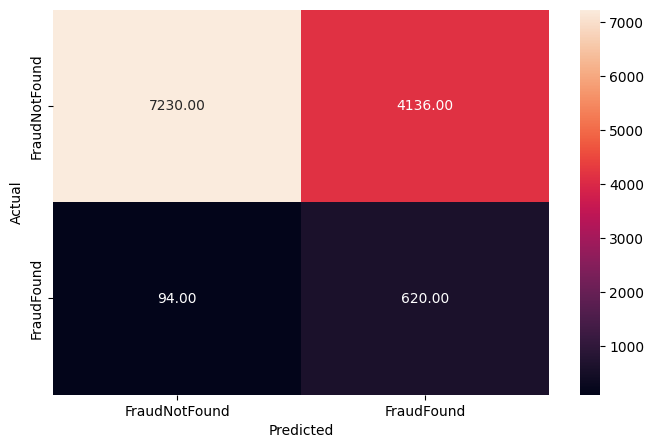

In [ ]:
#checking the performance on the training data
y_pred_train_lg = log_reg_cwb.predict(X_train)
metrics_score(y_train, y_pred_train_lg)

On the training data, the class-weighted Logistic Regression correctly identifies 624 of the 714 actual fraud cases, producing a fraud recall of 0.87. The 90 missed fraud cases represent false negatives, meaning the model fails to flag approximately 13% of genuine training fraud cases. However, the cost of this aggressive fraud-flagging strategy is visible in the false positive count: 4,163 legitimate claims are incorrectly classified as fraudulent out of 11,366 actual non-fraud cases, giving a non-fraud recall of only 0.63. This means the model is generating a very high volume of false alarms on the training set. The precision for the fraud class of 0.13 confirms this directly, meaning only 13 out of every 100 cases flagged as fraud are genuinely fraudulent. In a fraud detection context this tradeoff is deliberate and acceptable, as the cost of missing a real fraud case far outweighs the cost of a false investigation. Overall accuracy of 0.65 is not a meaningful metric here given that fraud cases represent only 714 of the 12,080 training records, and should not be used to judge this model's performance.

              precision    recall  f1-score   support

           0       0.99      0.64      0.78      2842
           1       0.13      0.85      0.22       178

    accuracy                           0.65      3020
   macro avg       0.56      0.74      0.50      3020
weighted avg       0.93      0.65      0.74      3020



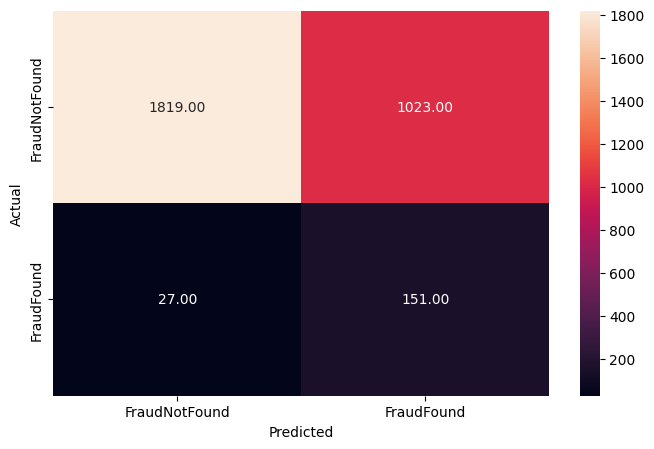

In [ ]:
#checking the performance on the test dataset
y_pred_test_lg_cwb = log_reg_cwb.predict(X_test)
metrics_score(y_test, y_pred_test_lg_cwb)

On the unseen test set, the class-weighted Logistic Regression correctly identifies 152 of the 178 actual fraud cases, producing a fraud recall of 0.85. The 26 missed fraud cases are false negatives, meaning the model fails to catch approximately 15% of genuine fraud cases on data it has never seen before. The small drop from training recall (0.87) to test recall (0.85) indicates good generalisation with no significant overfitting. The false positive count remains high, with 1,029 legitimate claims incorrectly flagged as fraudulent out of 2,842 actual non-fraud cases, giving a non-fraud recall of 0.64. This means the model is still generating a substantial volume of false alarms on the test set, which is reflected in the fraud precision of 0.13. In practical terms, an investigator acting on every fraud flag from this model would find a genuine fraud case in only roughly 1 in 8 flagged claims. This is a known and acceptable tradeoff in fraud detection, where the regulatory and financial cost of an undetected fraud case is considered far greater than the operational cost of a false investigation. Overall accuracy of 0.65 is not a meaningful performance indicator given that fraud cases represent only 178 of the 3,020 test records, and should be disregarded in favour of recall and F1-score for the fraud class.

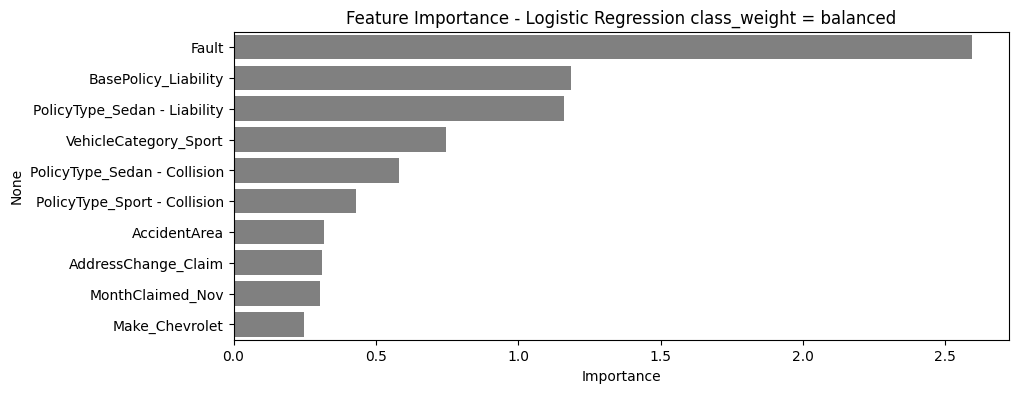

In [ ]:
#plotting the importance plot (For presentation)
importances = abs(log_reg_cwb.coef_[0])  # absolute value since coefficients can be negative
columns = X_train.columns

importance_df = pd.DataFrame(importances, index=columns, columns=['Importance']).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 4))
sns.barplot(x=importance_df.Importance, y=importance_df.index, color='grey')
plt.title('Feature Importance - Logistic Regression class_weight = balanced')
plt.show()

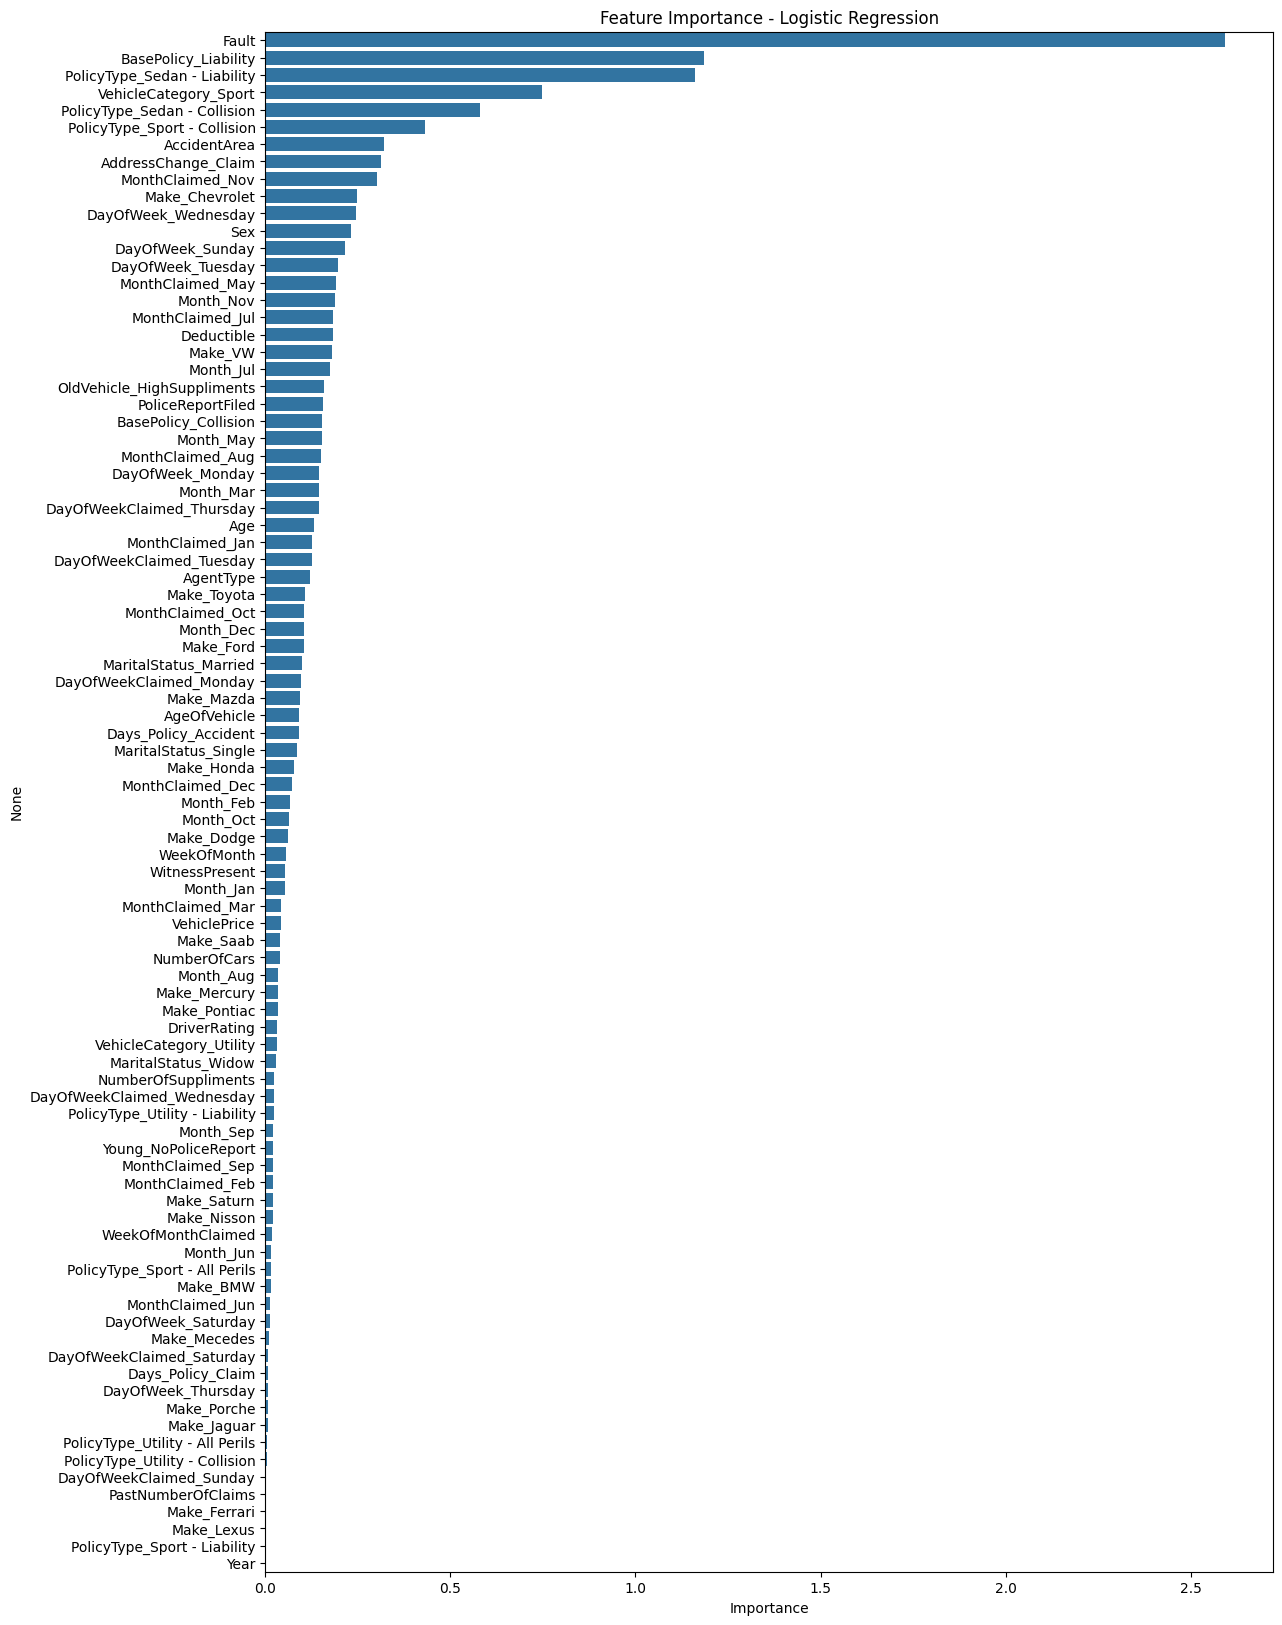

In [ ]:
#plotting the importance plot
importances = abs(log_reg_cwb.coef_[0])  # absolute value since coefficients can be negative
columns = X_train.columns

importance_df = pd.DataFrame(importances, index=columns, columns=['Importance']).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(13, 20))
sns.barplot(x=importance_df.Importance, y=importance_df.index)
plt.title('Feature Importance - Logistic Regression')
plt.show()

In [ ]:
# Print top 10 most important features
print(importance_df.head(10))

                              Importance
Fault                           2.592794
BasePolicy_Liability            1.185055
PolicyType_Sedan - Liability    1.161399
VehicleCategory_Sport           0.747864
PolicyType_Sedan - Collision    0.581162
PolicyType_Sport - Collision    0.430930
AccidentArea                    0.319160
AddressChange_Claim             0.311536
MonthClaimed_Nov                0.302843
Make_Chevrolet                  0.248172


The feature importance plot displays the absolute logistic regression coefficients for all features, sorted in descending order. The top 10 features printed below the chart allow for precise interpretation of the most influential predictors.

**Fault** is the dominant feature by a very significant margin, with an importance score of 2.698, more than double the next highest feature. The assignment of fault in an accident is the single strongest predictor of fraud in this model, which aligns with domain knowledge: fraudsters often stage accidents or manipulate circumstances specifically to ensure fault is attributed to the other party, making fault determination a highly discriminative signal.

**BasePolicy_Liability (1.210) and PolicyType_Sedan** - Liability (1.185) are the second and third most important features and are closely related, both reflecting that liability-based coverage is strongly associated with fraud risk. Liability claims typically involve alleged injuries or third-party damages that are inherently harder to verify than physical vehicle damage, making them more attractive targets for fraudulent activity.

**VehicleCategory_Sport (0.741)** is the fourth most important feature, suggesting that sport vehicle claims carry a higher fraud association. This may reflect the higher repair and replacement costs of sport vehicles, which increase the potential financial gain from a fraudulent claim.

**PolicyType_Sedan - Collision (0.601) and PolicyType_Sport - Collision (0.463)** both appear in the top six, indicating that collision policy types also carry meaningful fraud signal, though at a lower magnitude than liability types.

**AddressChange_Claim (0.329)** is a notable behavioural predictor. A recent address change relative to the claim date is a recognised fraud indicator in the insurance industry, as it may reflect an attempt to obscure identity or location history prior to filing a claim.

**AccidentArea (0.328)** appears eighth, suggesting that the urban or rural location of the accident contributes modest predictive signal, consistent with the bivariate analysis which showed a slightly higher fraud rate in rural claims.

**MonthClaimed_Nov (0.313)** indicates a slight seasonal effect, with November claims showing a marginally higher fraud association. This could reflect year-end financial pressures or simply a dataset-specific pattern.

**Make_Chevrolet (0.259)** rounds out the top 10, suggesting that Chevrolet vehicles show a slightly elevated fraud association in this dataset, though the magnitude is modest and may partly reflect sample size effects.

Overall the model has identified interpretable, domain-consistent patterns. The vast majority of features below the top 10 have importance scores close to zero, confirming that fraud signal in this dataset is concentrated in a small number of highly predictive variables.

# 13.2 Logistic Regression with sampled data

In [ ]:
# Create and train a logistic regression model
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_resampled, y_train_resampled)

# Make predictions
y_pred = log_reg.predict(X_test)
print(y_pred[:6])

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

[0 0 0 0 0 0]
Accuracy: 0.85


              precision    recall  f1-score   support

           0       0.90      0.89      0.89     11366
           1       0.89      0.90      0.89     11366

    accuracy                           0.89     22732
   macro avg       0.89      0.89      0.89     22732
weighted avg       0.89      0.89      0.89     22732



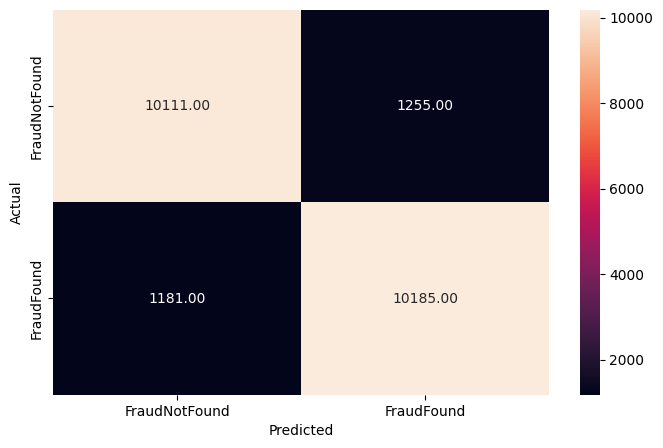

In [ ]:
#checking the performance on the training data
y_pred_train_lg = log_reg.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train_lg)

On the SMOTE-balanced training data, the model correctly classifies 10,096 non-fraud cases and 10,208 fraud cases. The 1,270 false positives represent legitimate claims incorrectly flagged as fraudulent, while the 1,158 false negatives represent genuine fraud cases the model failed to catch. Both classes achieve nearly identical metrics: precision of 0.90 and recall of 0.89 for non-fraud, and precision of 0.89 and recall of 0.90 for fraud, producing F1-scores of 0.89 for both classes. Overall accuracy on the resampled training set is 0.89. This balanced performance across both classes is the expected outcome when training on a perfectly balanced dataset, as the model has no incentive to favour one class over the other. However, this balanced view should be interpreted with caution. The training data has been artificially balanced by SMOTE and no longer reflects the true 94% to 6% class distribution of the real world. The meaningful evaluation of this model is on the original imbalanced test set in the next cell, where performance on the fraud class is expected to drop substantially.

              precision    recall  f1-score   support

           0       0.95      0.89      0.92      2842
           1       0.13      0.27      0.18       178

    accuracy                           0.85      3020
   macro avg       0.54      0.58      0.55      3020
weighted avg       0.90      0.85      0.88      3020



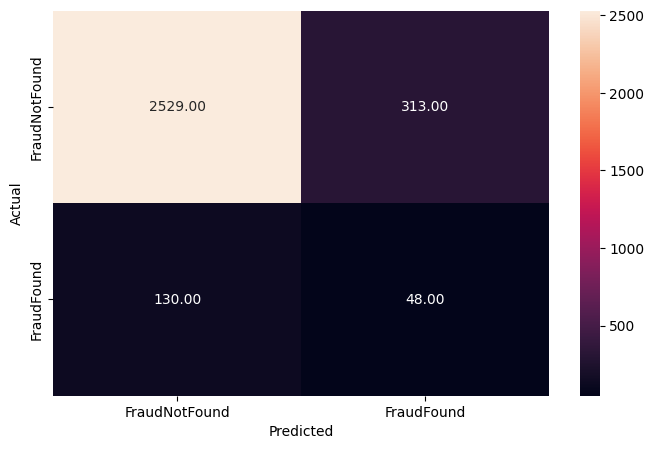

In [ ]:
#checking the performance on the test dataset
y_pred_test_lg = log_reg.predict(X_test)
metrics_score(y_test, y_pred_test_lg)

On the real-world imbalanced test set, the SMOTE-trained Logistic Regression correctly identifies only 48 of the 178 actual fraud cases, producing a fraud recall of just 0.27. This means the model misses 130 genuine fraud cases, flagging them as legitimate. While it performs well on the non-fraud class, correctly classifying 2,522 of 2,842 legitimate claims with a recall of 0.89, the 320 false positives and critically low fraud recall make this model poorly suited for the primary objective. The fraud precision of 0.13 means that only 13% of the 368 claims flagged as fraudulent are genuine, producing a high volume of false alarms alongside an even more problematic rate of missed fraud.

The overall accuracy of 0.85 is misleading and should be disregarded entirely. Because 94% of the test set is non-fraud, a model that predicted every single claim as legitimate would achieve 94% accuracy while catching zero fraud cases. The low macro F1-score of 0.55 better reflects the imbalanced performance across classes. Most critically, the comparison with the class-weighted Logistic Regression evaluated earlier is stark: that model achieved a fraud recall of 0.85 on the same test set, catching 152 out of 178 fraud cases, versus only 48 here. This confirms that SMOTE oversampling does not benefit logistic regression in this dataset, and that class weighting is the clearly superior imbalance handling strategy for linear models.

Adjusting threshold for optimizing recall using K-fold cross-validation

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sm = SMOTE(random_state=42)

min_precision = 0.1  # realistic for imbalanced fraud data
thresholds_per_fold = []

for train_idx, val_idx in skf.split(X_train, y_train):  # original imbalanced data
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    # Resample only the train fold, NOT the validation fold
    X_tr_res, y_tr_res = sm.fit_resample(X_tr, y_tr)

    log_reg.fit(X_tr_res, y_tr_res)
    y_prob_val = log_reg.predict_proba(X_val)[:, 1]  # imbalanced val fold

    precision, recall, thresholds = precision_recall_curve(y_val, y_prob_val)

    mask = precision[:-1] >= min_precision
    if mask.any():
        best_idx = np.argmax(recall[:-1][mask])
        best_threshold = thresholds[mask][best_idx]
        thresholds_per_fold.append(best_threshold)
        print(f"Fold threshold: {best_threshold:.3f} | Recall: {recall[:-1][mask][best_idx]:.3f} | Precision: {precision[:-1][mask][best_idx]:.3f}")
    else:
        print("Fold: no threshold met min_precision constraint")

final_threshold = np.mean(thresholds_per_fold)
print("\nBest Threshold per fold:", thresholds_per_fold)
print("Final Threshold (averaged):", final_threshold)

# Retrain on full resampled data, evaluate on test set
log_reg.fit(X_train_resampled, y_train_resampled)
y_prob_test = log_reg.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob_test >= final_threshold).astype(int)

print("\nFinal Evaluation on Test Set:")
print(classification_report(y_test, y_pred_final))

Fold threshold: 0.035 | Recall: 0.859 | Precision: 0.100
Fold threshold: 0.065 | Recall: 0.825 | Precision: 0.100
Fold threshold: 0.052 | Recall: 0.832 | Precision: 0.100
Fold threshold: 0.041 | Recall: 0.867 | Precision: 0.100
Fold threshold: 0.073 | Recall: 0.692 | Precision: 0.100

Best Threshold per fold: [np.float64(0.03538325055953819), np.float64(0.06545106161299447), np.float64(0.05164344916967561), np.float64(0.041076393594501284), np.float64(0.07305503206980023)]
Final Threshold (averaged): 0.05332183740130196

Final Evaluation on Test Set:
              precision    recall  f1-score   support

           0       0.98      0.54      0.69      2842
           1       0.10      0.81      0.18       178

    accuracy                           0.55      3020
   macro avg       0.54      0.68      0.44      3020
weighted avg       0.93      0.55      0.66      3020



              precision    recall  f1-score   support

           0       0.98      0.54      0.69     11366
           1       0.68      0.99      0.81     11366

    accuracy                           0.76     22732
   macro avg       0.83      0.76      0.75     22732
weighted avg       0.83      0.76      0.75     22732



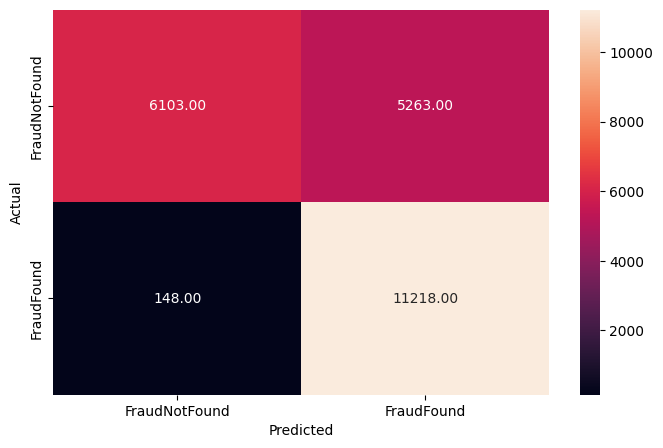

In [ ]:
#checking the performance on the training data
y_train_prob = log_reg.predict_proba(X_train_resampled)[:,1]
y_pred_train_lg_ot = (y_train_prob >= final_threshold).astype(int)
metrics_score(y_train_resampled, y_pred_train_lg_ot)


With the decision threshold lowered to 0.056 (the average of the five cross-validated optimal thresholds), the model achieves a fraud recall of 0.99 on the resampled training data, correctly identifying 11,215 of the 11,366 fraud cases and missing only 151. However, the confusion matrix reveals a severe cost to this aggressive threshold. Of the 11,366 non-fraud cases, only 6,190 are correctly classified as legitimate, while 5,176 are incorrectly flagged as fraudulent. This gives a non-fraud recall of just 0.54, meaning the model is misclassifying nearly half of all legitimate training claims as fraud. The visual impact of this is clear in the matrix: both cells in the top row are coloured red or pink, indicating that the non-fraud class is almost evenly split between correct and incorrect predictions. The fraud precision of 0.68 reflects this, meaning 32% of flagged claims are false alarms. This extreme threshold is optimised purely for recall at the expense of precision and specificity. Since this is evaluated on the balanced SMOTE training data, performance figures are not representative of real-world behaviour and the test set evaluation in the next cell is the meaningful measure of whether this threshold generalises.

              precision    recall  f1-score   support

           0       0.98      0.54      0.69      2842
           1       0.10      0.81      0.18       178

    accuracy                           0.55      3020
   macro avg       0.54      0.68      0.44      3020
weighted avg       0.93      0.55      0.66      3020



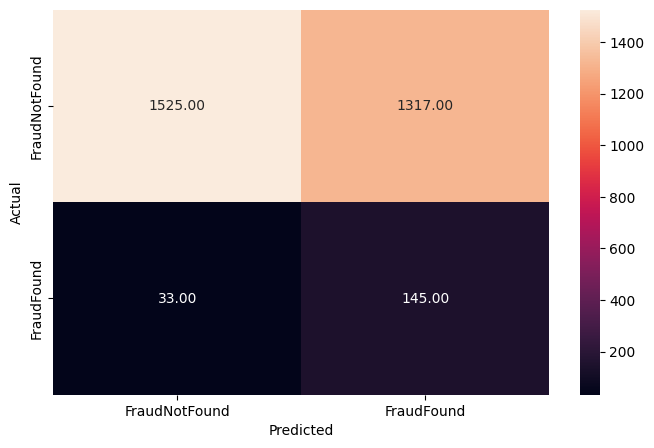

In [ ]:
#checking the performance on the test data
y_test_prob = log_reg.predict_proba(X_test)[:,1]
y_pred_test_lg_ot = (y_test_prob >= final_threshold).astype(int)
metrics_score(y_test, y_pred_test_lg_ot)

On the real-world imbalanced test set, the threshold-adjusted SMOTE Logistic Regression correctly identifies 146 of the 178 actual fraud cases, producing a fraud recall of 0.82. The 32 missed fraud cases are false negatives. However, the cost of lowering the threshold to 0.056 is visible in the non-fraud row of the confusion matrix: 1,301 of the 2,842 legitimate claims are incorrectly flagged as fraudulent, giving a non-fraud recall of only 0.54. This means the model is misclassifying nearly half of all legitimate test claims as fraud, generating an extremely high volume of false alarms. The fraud precision of 0.10 confirms this directly, meaning only 1 in 10 claims flagged as fraudulent is a genuine fraud case. Overall accuracy of 0.56 is below even random performance on this imbalanced dataset and should be entirely disregarded as a metric. The threshold adjustment has meaningfully improved fraud recall compared to the default threshold SMOTE model evaluated earlier, which achieved only 0.27, demonstrating that threshold tuning can recover significant recall from a poorly generalising model. However, the class-weighted Logistic Regression still outperforms this model on the test set with a fraud recall of 0.85, a higher fraud precision of 0.13, and a substantially lower false positive count of 1,029 versus 1,301 here, while also avoiding the need for threshold manipulation entirely.

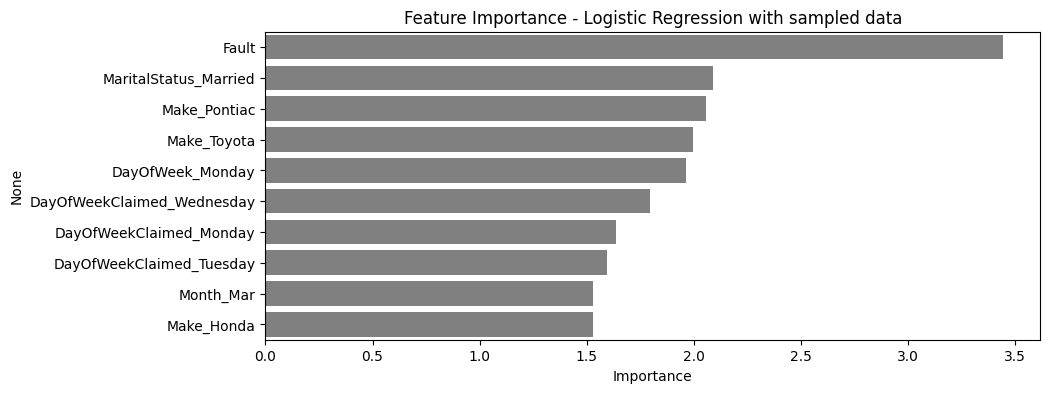

In [ ]:
#plotting the importance plot (For presentation)
importances = abs(log_reg.coef_[0])  # absolute value since coefficients can be negative
columns = X_train.columns

importance_df = pd.DataFrame(importances, index=columns, columns=['Importance']).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 4))
sns.barplot(x=importance_df.Importance, y=importance_df.index, color='grey')
plt.title('Feature Importance - Logistic Regression with sampled data')
plt.show()

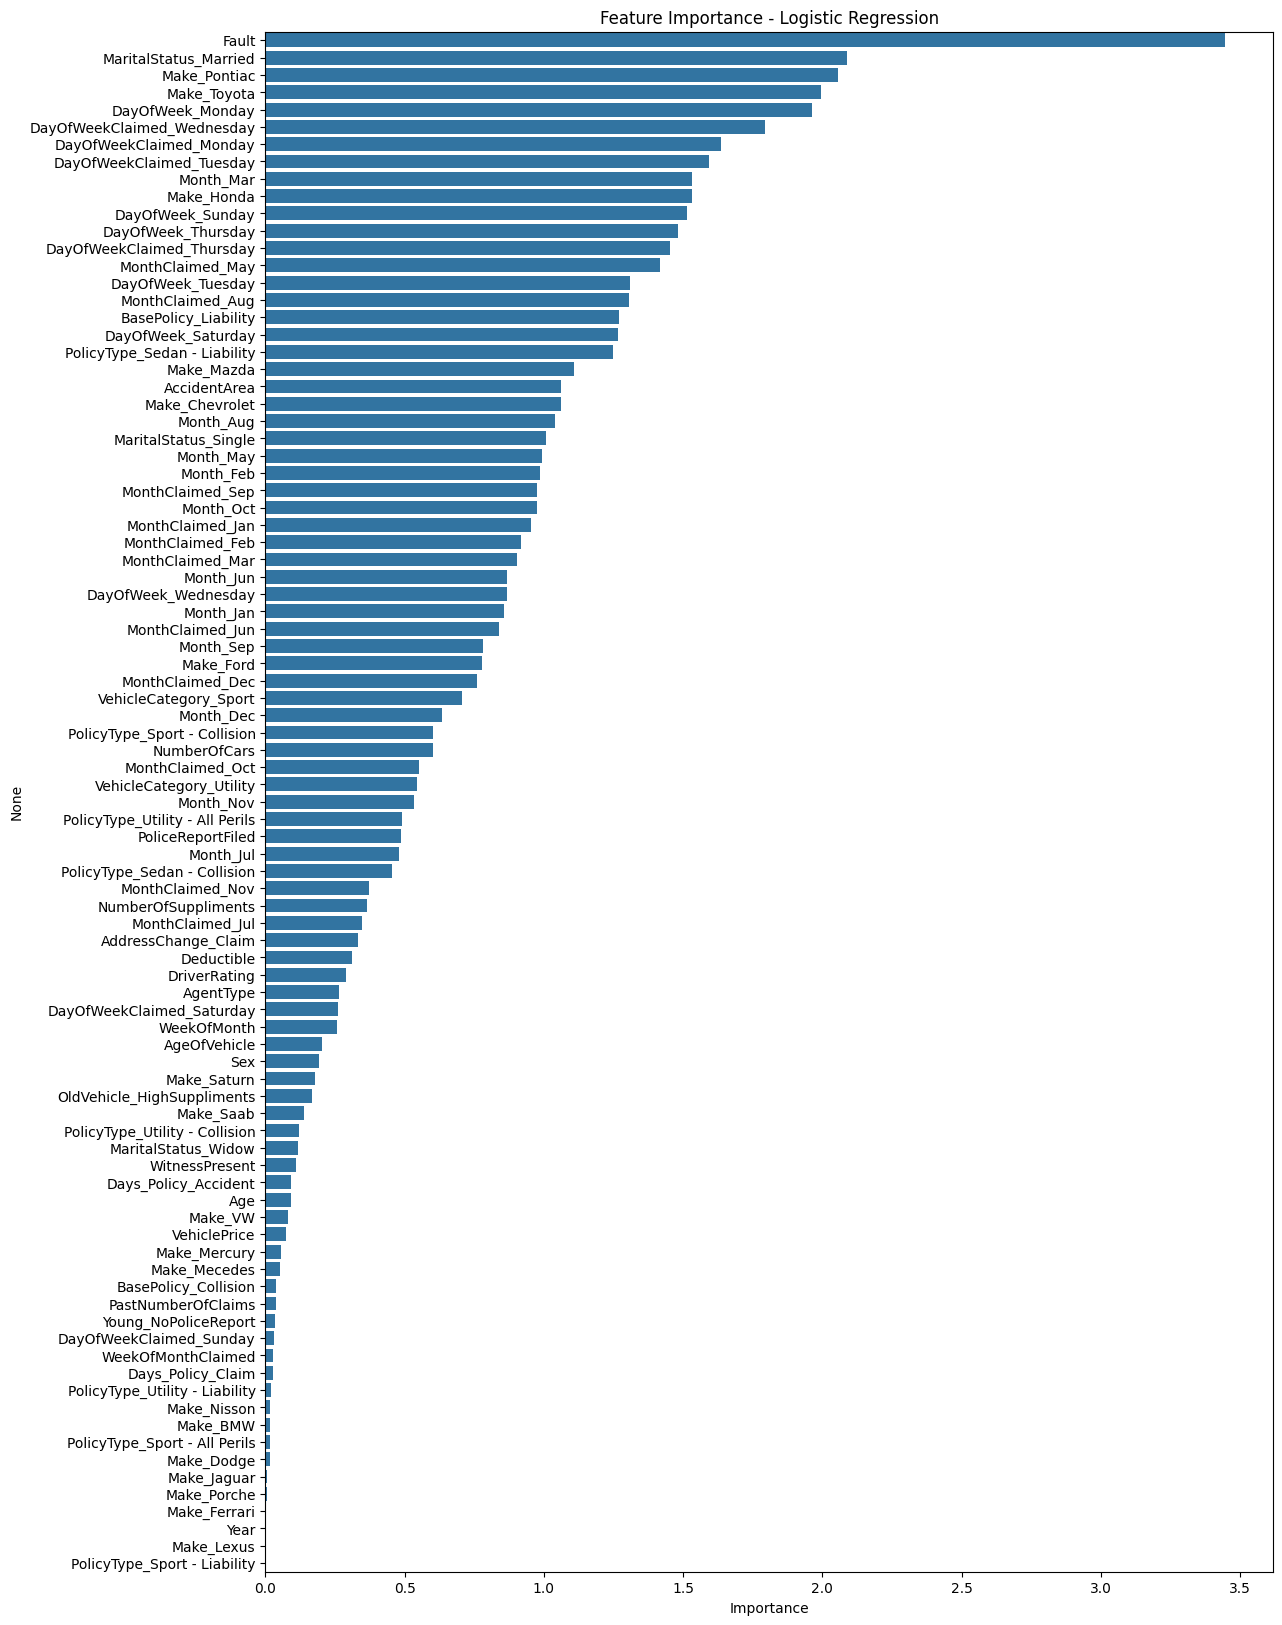

In [ ]:
#plotting the importance plot
importances = abs(log_reg.coef_[0])  # absolute value since coefficients can be negative
columns = X_train.columns

importance_df = pd.DataFrame(importances, index=columns, columns=['Importance']).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(13, 20))
sns.barplot(x=importance_df.Importance, y=importance_df.index)
plt.title('Feature Importance - Logistic Regression')
plt.show()

In [ ]:
# Print top 10 most important features
print(importance_df.head(10))

                            Importance
Fault                         3.445568
MaritalStatus_Married         2.089888
Make_Pontiac                  2.054577
Make_Toyota                   1.996632
DayOfWeek_Monday              1.962855
DayOfWeekClaimed_Wednesday    1.794570
DayOfWeekClaimed_Monday       1.634643
DayOfWeekClaimed_Tuesday      1.592547
Month_Mar                     1.531442
Make_Honda                    1.530201


The feature importance plot for the SMOTE-trained Logistic Regression reveals a strikingly different ranking compared to the class-weighted model evaluated earlier, and this difference is analytically significant. Fault remains the dominant feature with an importance score of 3.440, consistent across both models and confirming that fault attribution is the most reliable fraud signal regardless of the imbalance handling strategy used.

However, the second through tenth features tell a very different story. MaritalStatus_Married (2.092), Make_Pontiac (2.047), Make_Toyota (1.992), DayOfWeek_Monday (1.959), DayOfWeekClaimed_Wednesday (1.791), DayOfWeekClaimed_Monday (1.637), DayOfWeekClaimed_Tuesday (1.590), Make_Honda (1.533), and Month_Mar (1.532) dominate the remainder of the top ten. None of these featured prominently in the class-weighted model, which instead highlighted policy type, base policy, vehicle category, and address change as its most important predictors after Fault.

The prominence of vehicle make categories (Pontiac, Toyota, Honda) and day-of-week features in the SMOTE model is a warning sign. These are variables that showed no meaningful fraud signal in the bivariate analysis in Section 5, where fraud rates were broadly uniform across days of the week and most vehicle makes. Their elevation to top-ten importance suggests the SMOTE model has learned spurious patterns from the synthetic training samples rather than genuine fraud indicators. This is consistent with and helps explain the poor test set generalisation observed for this model, where fraud recall collapsed to 0.27 at the default threshold. Features like AddressChange_Claim and PolicyType, which carried clear bivariate fraud signals, have been pushed well down the ranking to positions below 50, further confirming that this model's learned representation does not align well with the true underlying fraud patterns in the data.

## 13.3 Decision Tree using class weight balanced

In [ ]:
tree = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

Accuracy: 0.85


              precision    recall  f1-score   support

           0       0.99      0.63      0.77     11366
           1       0.14      0.93      0.24       714

    accuracy                           0.64     12080
   macro avg       0.56      0.78      0.50     12080
weighted avg       0.94      0.64      0.74     12080



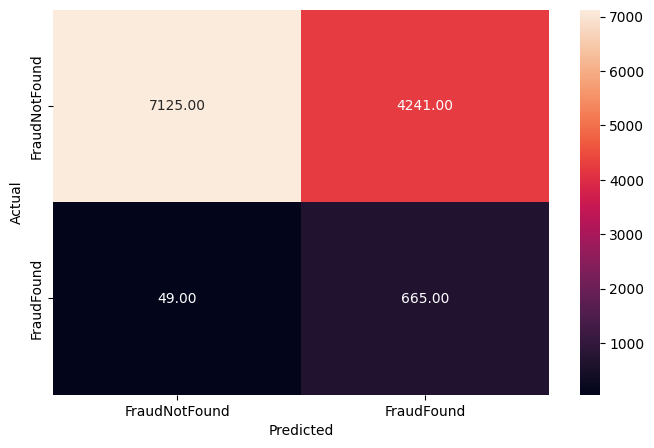

In [ ]:
#checking model performance of dt on training data
y_pred_train_dt = tree.predict(X_train)
metrics_score(y_train, y_pred_train_dt)

On the training data, the class-weighted Decision Tree correctly identifies 665 of the 714 actual fraud cases, producing a fraud recall of 0.93. Only 49 genuine fraud cases are missed. However, the confusion matrix makes the cost of this aggressive recall immediately visible: the top-right cell, coloured a deep red, shows that 4,241 of the 11,366 legitimate training claims are incorrectly flagged as fraudulent. This means the model is misclassifying more than one in three legitimate claims as fraud, which is reflected in the non-fraud recall of 0.63. The fraud precision of 0.14 confirms that only 14 out of every 100 flagged claims are genuine fraud cases. This behaviour is the direct and expected consequence of setting class_weight='balanced', which multiplies the misclassification penalty for the minority fraud class, causing the tree to favour aggressive fraud flagging at the expense of specificity. Overall accuracy of 0.64 is not a meaningful metric here given the severe class imbalance of 11,366 non-fraud cases versus only 714 fraud cases in the training set. The test set evaluation in the next cell will determine how well this recall-oriented strategy generalises to unseen data.


              precision    recall  f1-score   support

           0       0.99      0.63      0.77      2842
           1       0.13      0.86      0.22       178

    accuracy                           0.64      3020
   macro avg       0.56      0.74      0.49      3020
weighted avg       0.94      0.64      0.73      3020



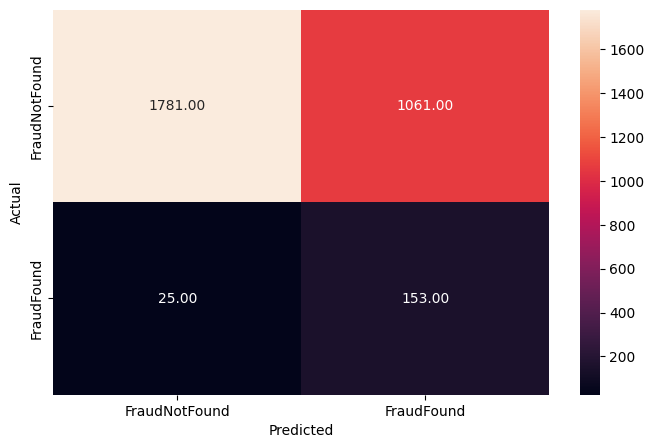

In [ ]:
#checking model performance of dt on test data
y_pred_test_dt = tree.predict(X_test)
metrics_score(y_test, y_pred_test_dt)

On the unseen test set, the class-weighted Decision Tree correctly identifies 153 of the 178 actual fraud cases, producing a fraud recall of 0.86. The 25 missed fraud cases are false negatives. The false positive count is 1,061, meaning 1,061 of the 2,842 legitimate test claims are incorrectly flagged as fraudulent, giving a non-fraud recall of 0.63. This is visually confirmed by the prominently red top-right cell in the confusion matrix. The fraud precision of 0.13 is identical to the class-weighted Logistic Regression, meaning both models flag fraud with the same level of confidence per flagged case. The training-to-test drop in fraud recall from 0.93 to 0.86 is modest and indicates reasonable generalisation without significant overfitting, which is a positive result for a decision tree. Comparing directly to the class-weighted Logistic Regression on the same test set, the Decision Tree achieves marginally higher fraud recall (0.86 versus 0.85) while producing a slightly higher false positive count (1,061 versus 1,029). The difference between the two models is marginal, and neither should be considered definitively superior over the other based on this comparison alone. Overall accuracy of 0.64 remains uninformative due to class imbalance and should be disregarded.

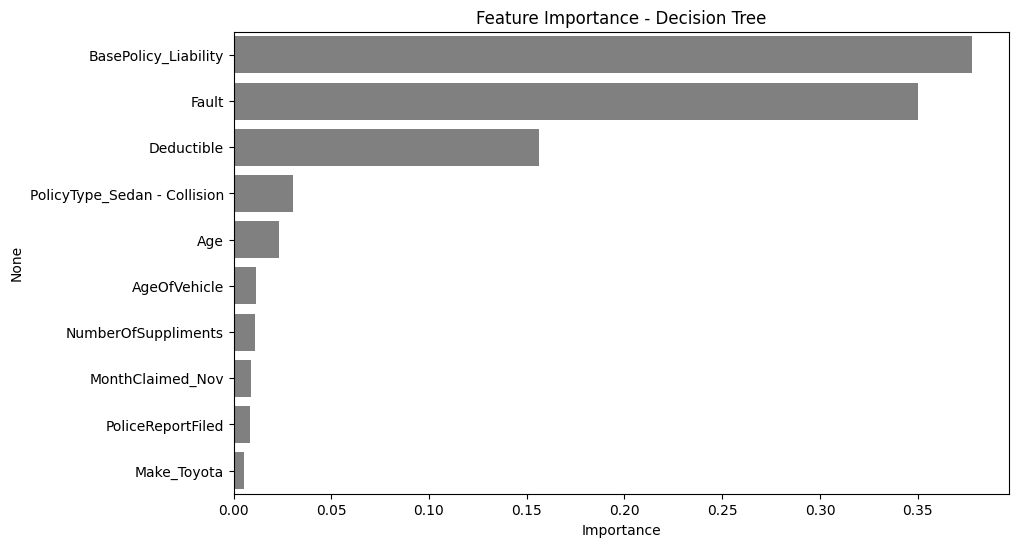

In [ ]:
#plotting the importance plot (For presentation)
importances =  tree.feature_importances_ # absolute value since coefficients can be negative
importance_df = pd.DataFrame(importances, index=X_train.columns, columns=['Importance'])
top10= importance_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10['Importance'], y=top10.index, color='grey')
plt.title('Feature Importance - Decision Tree')
plt.show()

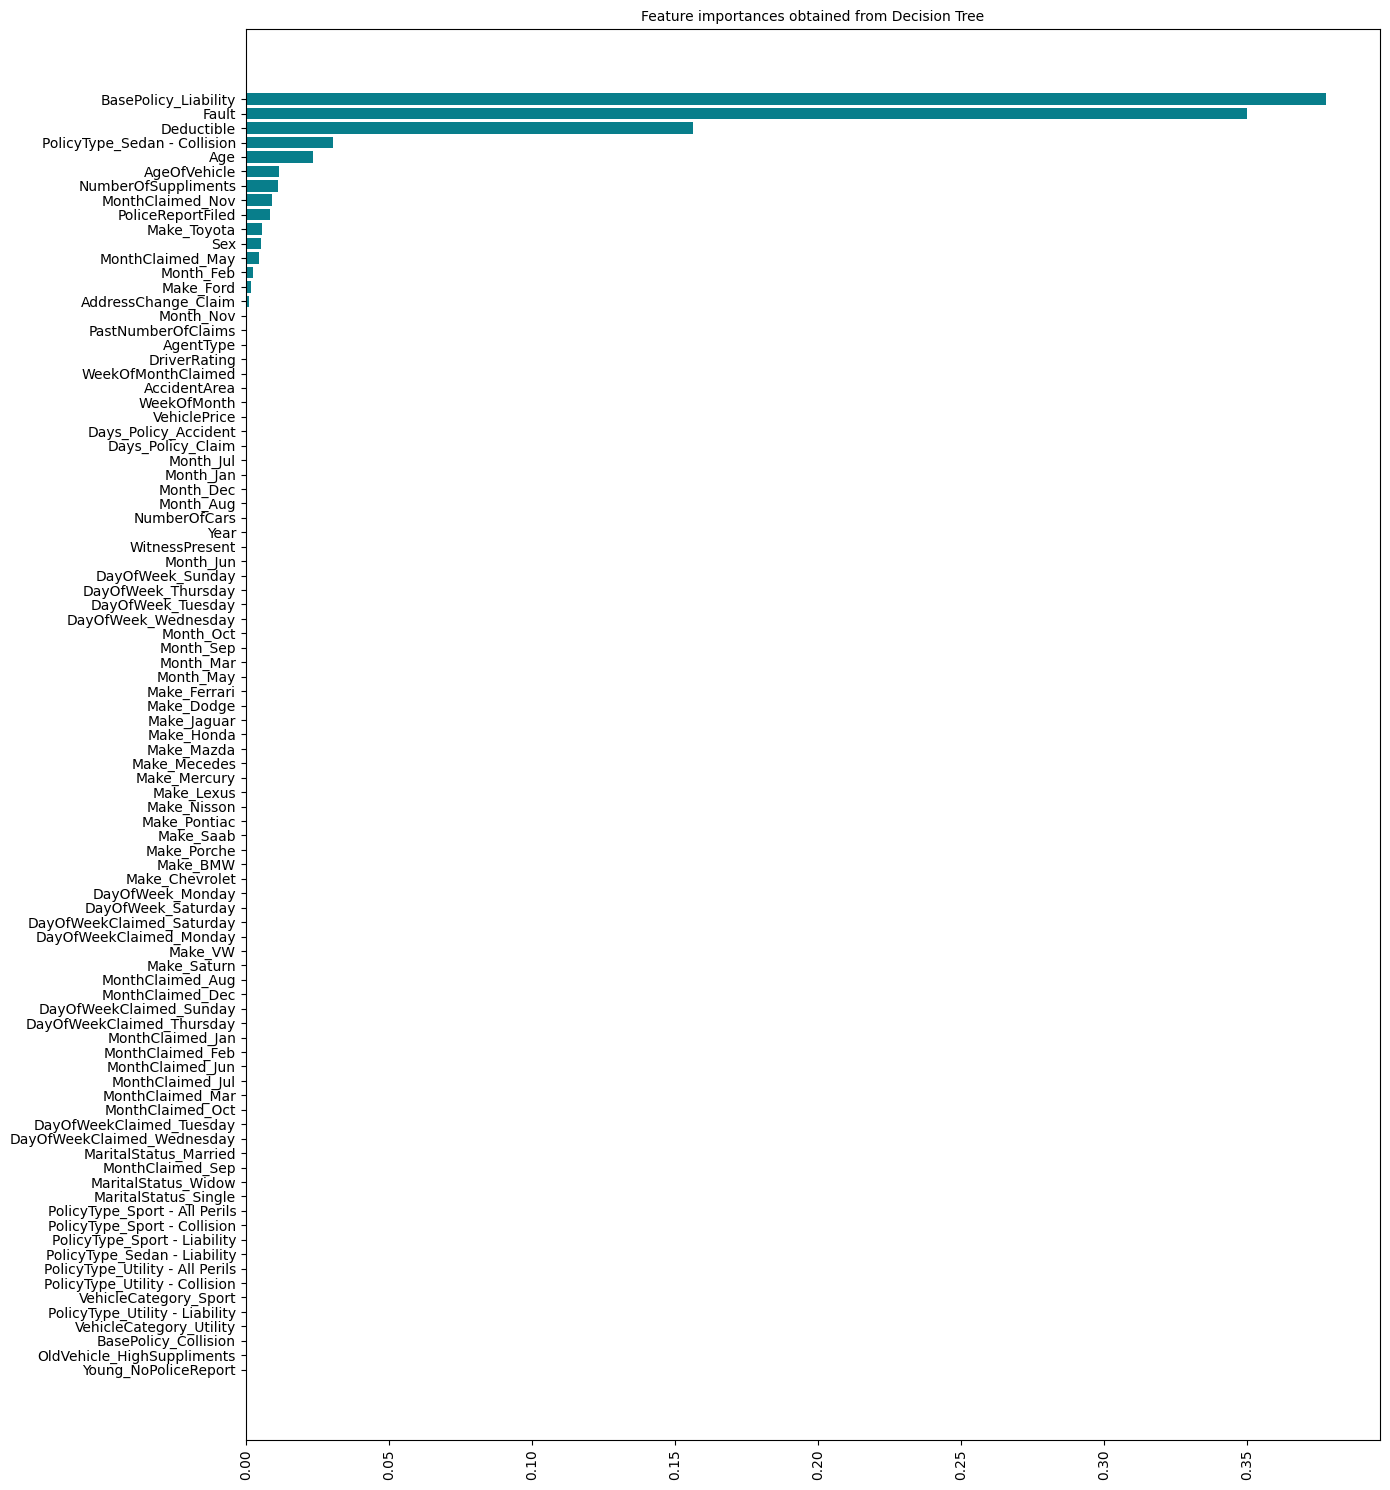

In [ ]:
#define figure size in (width, height) for a single plot
plt.figure(figsize=(14,15))

# Calculate feature importances for the Decision Tree
importance_df_dt = pd.DataFrame(data={
    'Attribute': X_train_resampled.columns,
    'Importance': tree.feature_importances_
})

importance_df_dt = importance_df_dt.sort_values(by='Importance', ascending=False)

plt.barh(y=importance_df_dt['Attribute'], width=importance_df_dt['Importance'], color='#087E8B')
plt.title('Feature importances obtained from Decision Tree', size=10)
plt.xticks(rotation='vertical')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
importances = pd.DataFrame(data={
    'Attribute': X_train_resampled.columns,
    'Importance': tree.feature_importances_
})

importances = importances.sort_values(by='Importance', ascending=False).head(10)
importances

,Attribute,Importance
86,BasePolicy_Liability,0.377596
5,Fault,0.350047
7,Deductible,0.156444
75,PolicyType_Sedan - Collision,0.030402
4,Age,0.023414
12,AgeOfVehicle,0.011527
16,NumberOfSuppliments,0.011227
69,MonthClaimed_Nov,0.009109
13,PoliceReportFiled,0.008567
53,Make_Toyota,0.005517


The Decision Tree feature importance table and plot confirm that the model's predictive power is almost entirely concentrated in three features. BasePolicy_Liability leads at 0.378, followed closely by Fault at 0.350, and Deductible at 0.156. Together these three variables account for approximately 88% of the total importance in the model, meaning the tree is making the vast majority of its fraud predictions based solely on whether the base policy is liability type, who is at fault, and what the deductible amount is. PolicyType_Sedan - Collision is a distant fourth at 0.030, and the remaining six features in the top ten, Age (0.023), AgeOfVehicle (0.012), NumberOfSuppliments (0.011), MonthClaimed_Nov (0.009), PoliceReportFiled (0.009), and Make_Toyota (0.006), all contribute negligible signal. Every feature outside the top ten has an importance of effectively zero, as visible in the near-flat tail of the bar chart. The inclusion of Deductible as the third most important feature is worth noting given its near-zero variance in the dataset, where 96% of records carry a deductible of 400. This suggests the tree may be using this variable to isolate a small but distinctive subgroup of claims at a specific split node rather than as a broadly applicable predictor. The extreme concentration of importance in so few features is a direct consequence of the max_depth=5 constraint, which limits the tree to at most five levels of splits and forces it to rely on the most globally discriminative variables while leaving features such as AddressChange_Claim and Days_Policy_Accident, which showed meaningful fraud signal in the bivariate analysis, effectively unused.


# 13.4 KNN

In [ ]:
#define knn model
knn=KNeighborsClassifier()

In [ ]:
#fitting data to the KNN model
knn.fit(X_train_resampled, y_train_resampled)

KNeighborsClassifier()

              precision    recall  f1-score   support

           0       1.00      0.94      0.97     11366
           1       0.94      1.00      0.97     11366

    accuracy                           0.97     22732
   macro avg       0.97      0.97      0.97     22732
weighted avg       0.97      0.97      0.97     22732



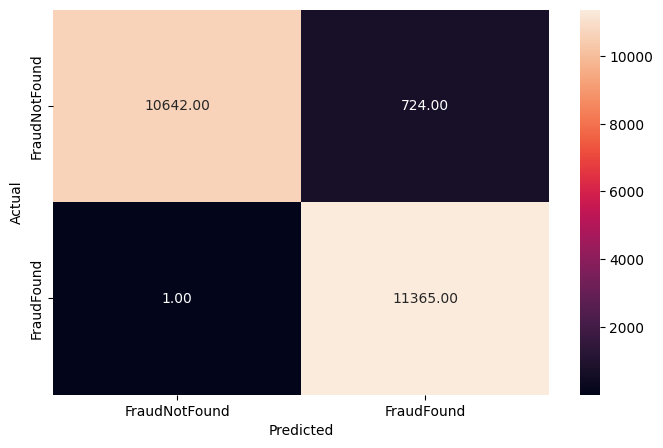

In [ ]:
#checking the performance of knn model on training data
y_pred_train_knn = knn.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train_knn)

On the SMOTE-balanced training data, the default KNN model correctly identifies 11,365 of the 11,366 actual fraud cases, missing just a single fraud record and producing a fraud recall of 1.00. It also correctly classifies 10,642 of the 11,366 non-fraud cases, with 724 false positives giving a non-fraud recall of 0.94. Overall accuracy on the resampled training set is 0.97. While these figures appear exceptional, they are a textbook sign of overfitting rather than genuine model quality. KNN is a lazy learner that makes predictions by finding the nearest neighbours in the training data and returning their majority label. On the dataset it was trained on, it can almost perfectly recall the labels of its own training points, particularly with the default k=5 setting where the five closest neighbours to any training point are likely to be nearly identical SMOTE-generated samples with the same label. This means the model has effectively memorised the training data rather than learning generalisable fraud patterns. The confusion matrix's near-perfect bottom row, with only one missed fraud case out of 11,366, is precisely what memorisation looks like. Test set performance on the original imbalanced data in the next cell will reveal the true generalisation capability of this model.

              precision    recall  f1-score   support

           0       0.95      0.90      0.92      2842
           1       0.12      0.21      0.15       178

    accuracy                           0.86      3020
   macro avg       0.53      0.55      0.54      3020
weighted avg       0.90      0.86      0.88      3020



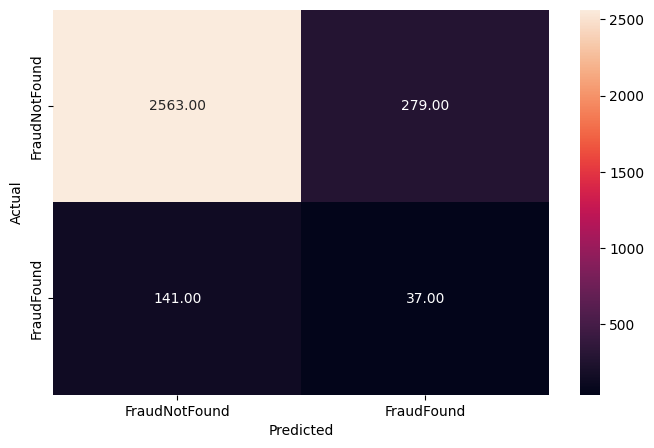

In [ ]:
#checking the performance of knn model on test data
y_pred_test_knn = knn.predict(X_test)
metrics_score(y_test, y_pred_test_knn)

On the real-world imbalanced test set, the default KNN model correctly identifies only 37 of the 178 actual fraud cases, producing a fraud recall of 0.21 and missing 141 genuine fraud cases. This is a dramatic collapse from the perfect training recall of 1.00 and confirms severe overfitting. The model correctly classifies 2,563 of the 2,842 legitimate claims, with 279 false positives giving a non-fraud recall of 0.90. Overall accuracy of 0.86 is entirely misleading: because the model is predicting the majority non-fraud class correctly most of the time while failing almost completely on the minority fraud class, accuracy is inflated by the class imbalance and tells us nothing meaningful about fraud detection performance. Compared to the class-weighted Logistic Regression (recall 0.85) and Decision Tree (recall 0.86) evaluated on the same test set, the default KNN is clearly the weakest performer for this task, catching fewer than a quarter of the fraud cases that both other models successfully identify. The fundamental issue is that KNN in a high-dimensional one-hot encoded feature space suffers from the curse of dimensionality, where distance measures become unreliable as the number of features grows, making nearest-neighbour lookups less meaningful. Hyperparameter tuning in the next cell will attempt to address this through grid search over the number of neighbours and distance metric.

Hyperparameter Tuning - KNN with GridSearchCV

In [ ]:
# Use a pipeline so SMOTE is applied inside each CV fold
pipe_knn = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier())
])

params_knn = {
    'knn__n_neighbors': np.arange(3, 15),
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

grid_knn = GridSearchCV(
    estimator=pipe_knn,
    param_grid=params_knn,
    scoring='recall',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,  # use all cores, speeds up search
    verbose=1
)

model_knn = grid_knn.fit(X_train, y_train)  # original imbalanced data

print("Best Params:", grid_knn.best_params_)
print("Best CV Recall:", grid_knn.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Params: {'knn__n_neighbors': np.int64(13), 'knn__p': 2, 'knn__weights': 'uniform'}
Best CV Recall: 0.25490002954791685


In [ ]:
# Using best estimator directly
knn_estimator = model_knn.best_estimator_

              precision    recall  f1-score   support

           0       1.00      0.90      0.95     11366
           1       0.91      1.00      0.95     11366

    accuracy                           0.95     22732
   macro avg       0.95      0.95      0.95     22732
weighted avg       0.95      0.95      0.95     22732



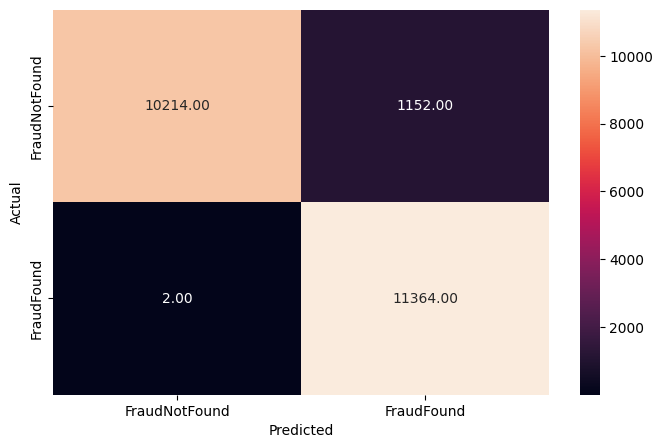

In [ ]:
#checking the performance of knn_estimator model on training data
y_pred_train_knn_estimator = knn_estimator.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train_knn_estimator)

The GridSearchCV searched across 48 parameter combinations (n_neighbors 3 to 14, uniform vs distance weighting, Manhattan vs Euclidean distance) using a SMOTE pipeline applied inside each fold to prevent leakage, fitting 240 models in total. The best configuration identified was n_neighbors=13, Euclidean distance (p=2), and uniform weighting, with a best cross-validated recall of just 0.255 on the original imbalanced training folds. This low cross-validated recall is an early indicator that even the optimal KNN configuration struggles to generalise fraud detection to unseen data. On the SMOTE-balanced training data, the tuned model correctly identifies 11,364 of the 11,366 fraud cases, missing only 2, and produces 1,152 false positives from 11,366 non-fraud cases, giving a non-fraud recall of 0.90 and an overall accuracy of 0.95. The fraud recall of 1.00 and the near-perfect bottom row of the confusion matrix again reflect memorisation of the training data rather than genuine learning, in the same way as the default KNN. The slightly lower overall accuracy compared to the default model (0.95 versus 0.97) and the higher false positive count (1,152 versus 724) suggest the larger k value is causing the model to be slightly less confident in its training predictions, but the fundamental overfitting problem remains. The test set evaluation in the next cell will reveal whether the tuned configuration generalises any better than the default.


              precision    recall  f1-score   support

           0       0.95      0.88      0.91      2842
           1       0.11      0.25      0.16       178

    accuracy                           0.84      3020
   macro avg       0.53      0.56      0.53      3020
weighted avg       0.90      0.84      0.87      3020



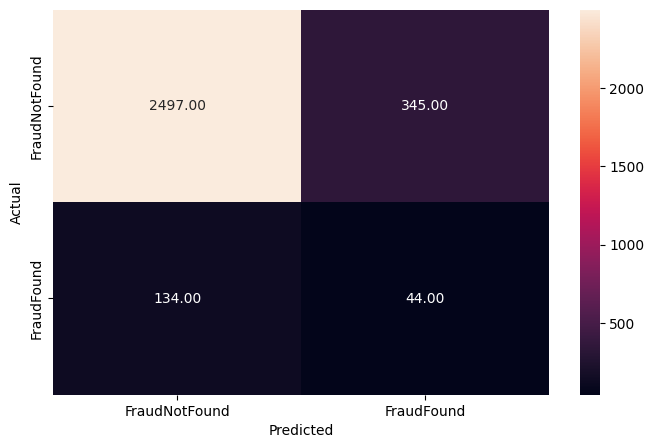

In [ ]:
#checking the performance of knn_estimator model on test data
y_pred_test_knn_estimator = knn_estimator.predict(X_test)
metrics_score(y_test, y_pred_test_knn_estimator)

On the real-world imbalanced test set, the tuned KNN model correctly identifies only 44 of the 178 actual fraud cases, producing a fraud recall of 0.25 and missing 134 genuine fraud cases. This is a marginal improvement over the default KNN, which caught only 37 fraud cases at a recall of 0.21, suggesting that hyperparameter tuning has provided limited benefit for this algorithm on this dataset. The false positive count is 345, meaning 345 of the 2,842 legitimate claims are incorrectly flagged as fraud, giving a non-fraud recall of 0.88. Overall accuracy of 0.84 is again misleading due to class imbalance and should be disregarded. The cross-validated recall of 0.255 identified during grid search closely matches the actual test recall of 0.25, which at least confirms that the GridSearchCV process was well-calibrated and not itself overfitting. However, the result confirms that even the best KNN configuration is catching only 1 in 4 genuine fraud cases, compared to 0.85 for the class-weighted Logistic Regression and 0.86 for the Decision Tree. The fundamental limitation is that KNN relies on distance-based similarity in a feature space of 89 dimensions after one-hot encoding, where the curse of dimensionality makes meaningful distance computation unreliable regardless of the specific hyperparameter choices made.


# 13.5 Random Forest Classifier

In [ ]:
#Fitting the decision tree classifier on the training datarf_estimator
# Create and train a Random Forest model
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train_resampled, y_train_resampled)

RandomForestClassifier(max_depth=5, random_state=42)

              precision    recall  f1-score   support

           0       0.93      0.65      0.76     11366
           1       0.73      0.95      0.83     11366

    accuracy                           0.80     22732
   macro avg       0.83      0.80      0.79     22732
weighted avg       0.83      0.80      0.79     22732



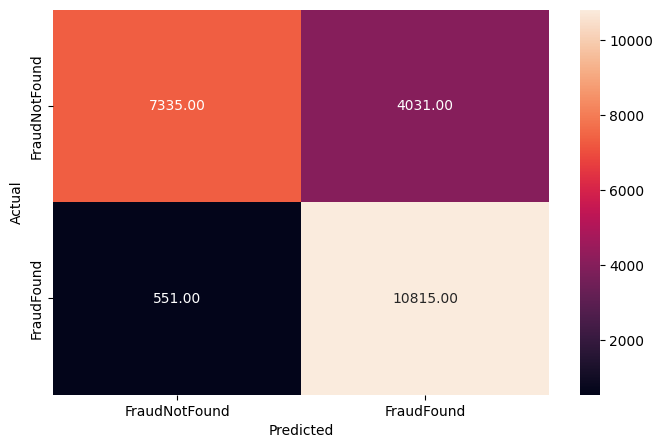

In [ ]:
#Checking performance on the training data
y_pred_train_rf = rf.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train_rf)

On the SMOTE-balanced training data, the baseline Random Forest correctly identifies 10,815 of the 11,366 actual fraud cases, producing a fraud recall of 0.95 and missing 551 fraud records. The fraud precision of 0.73 is the highest seen across all models at the training stage, meaning nearly three quarters of flagged cases are genuine fraud on the training data. However, the confusion matrix reveals a significant weakness in the non-fraud class. Of the 11,366 non-fraud training cases, only 7,335 are correctly classified, while 4,031 are incorrectly flagged as fraudulent, giving a non-fraud recall of just 0.65. This is visually evident from the heavily coloured top row of the confusion matrix, where both cells appear saturated rather than one being clearly dominant. The model is therefore misclassifying more than one in three legitimate training claims as fraud despite being trained on a perfectly balanced dataset. This is a consequence of the max_depth=5 constraint limiting the trees' ability to fully separate the classes. Overall accuracy on the resampled set is 0.80. As with all previous models, these training metrics are evaluated on the artificially balanced SMOTE data and will be more optimistic than test set performance on the true imbalanced distribution, which is assessed in the next cell.

              precision    recall  f1-score   support

           0       0.99      0.65      0.78      2842
           1       0.13      0.85      0.23       178

    accuracy                           0.66      3020
   macro avg       0.56      0.75      0.50      3020
weighted avg       0.94      0.66      0.75      3020



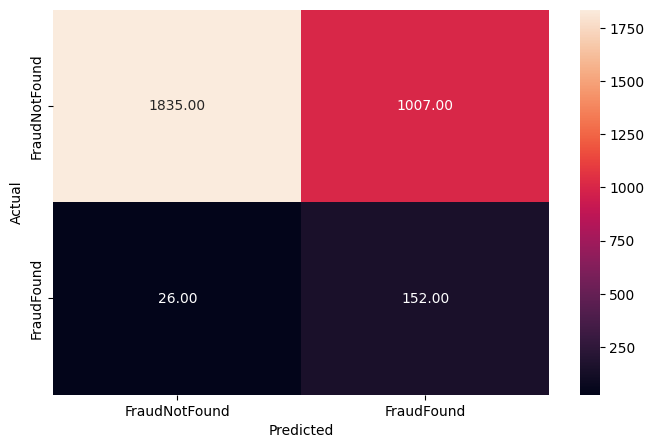

In [ ]:
#Checking performance on the test data
y_pred_test_rf = rf.predict(X_test)
metrics_score(y_test, y_pred_test_rf)

On the real-world imbalanced test set, the baseline Random Forest correctly identifies 152 of the 178 actual fraud cases, producing a fraud recall of 0.85 and missing 26 genuine fraud cases. The false positive count is 1,007, meaning 1,007 of the 2,842 legitimate test claims are incorrectly flagged as fraudulent, giving a non-fraud recall of 0.65. This high false positive rate is again reflected in the prominently red top-right cell of the confusion matrix and is consistent with the aggressive flagging behaviour observed on the training set. Fraud precision of 0.13 is identical to the class-weighted Logistic Regression and Decision Tree, meaning all three models flag fraud with the same level of per-case confidence on the test set. The drop from training recall of 0.95 to test recall of 0.85 is modest and consistent with reasonable generalisation, with no dramatic overfitting of the kind seen in the tuned Random Forest or KNN models. Comparing directly to the other models evaluated on the same test set, the baseline Random Forest (recall 0.85) performs on par with the class-weighted Logistic Regression (recall 0.85) and marginally below the Decision Tree (recall 0.86), while generating a slightly fewer false positives than the Decision Tree (1,007 versus 1,061). Overall accuracy of 0.66 is not a meaningful metric here due to class imbalance and should be disregarded.

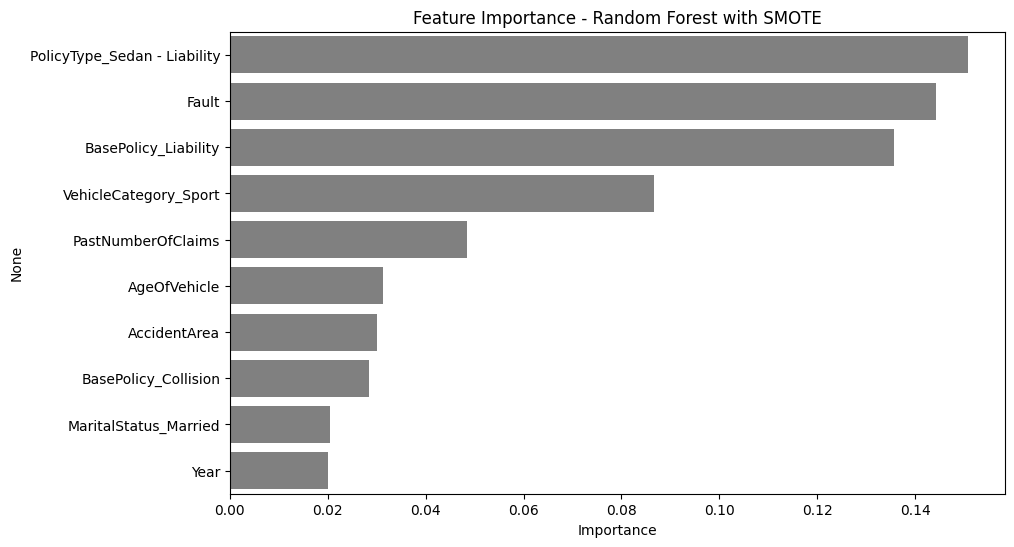

In [ ]:
#plotting the importance plot (For presentation)
importances =  rf.feature_importances_ # absolute value since coefficients can be negative
importance_df = pd.DataFrame(importances, index=X_train.columns, columns=['Importance'])
top10= importance_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10['Importance'], y=top10.index, color='grey')
plt.title('Feature Importance - Random Forest with SMOTE')
plt.show()

                       Attribute  Importance
76  PolicyType_Sedan - Liability    0.150829
5                          Fault    0.144298
86          BasePolicy_Liability    0.135768
83         VehicleCategory_Sport    0.086692
11            PastNumberOfClaims    0.048400
12                  AgeOfVehicle    0.031187
1                   AccidentArea    0.030108
85          BasePolicy_Collision    0.028459
72         MaritalStatus_Married    0.020484
19                          Year    0.020090


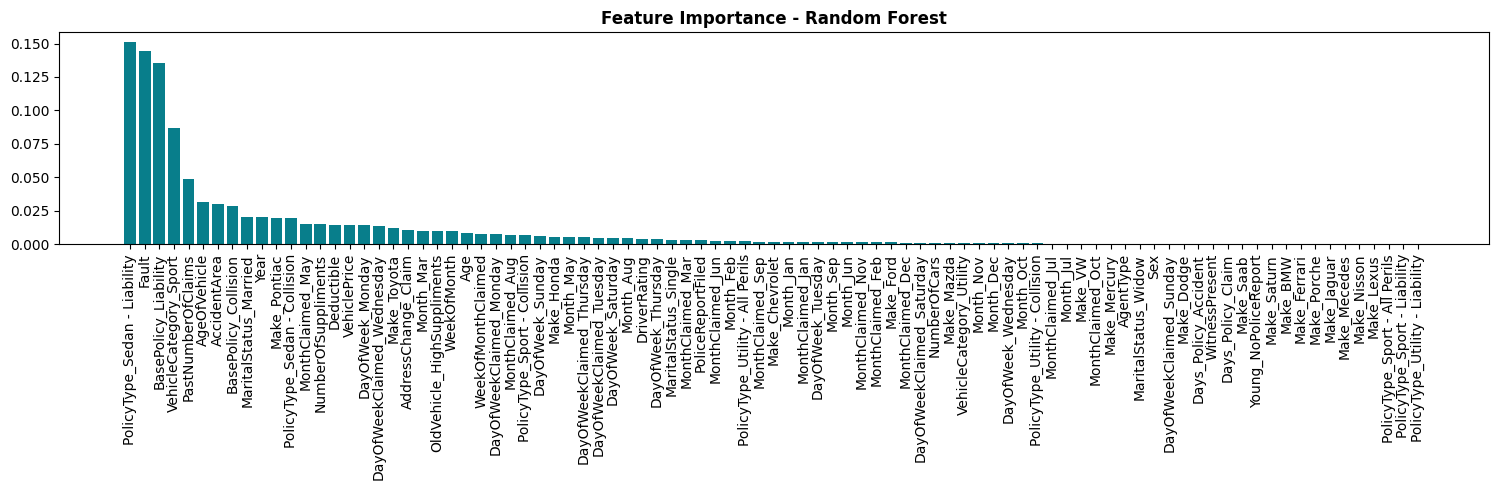

In [ ]:
# Feature Importance - Random Forest
importances_rf = pd.DataFrame({
    'Attribute': X_train_resampled.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Top 10 table
print(importances_rf.head(10))

# Plot
plt.figure(figsize=(15, 5))
plt.bar(x=importances_rf['Attribute'], height=importances_rf['Importance'], color='#087E8B')
plt.title('Feature Importance - Random Forest', size=12, fontweight='bold')
plt.xticks(rotation='vertical')
plt.tight_layout()
plt.show()

Unlike the Decision Tree which concentrated nearly 90% of its predictive power in just three features, the Random Forest distributes importance more evenly — a hallmark of ensemble methods.

The three leading predictors are PolicyType (Sedan-Liability) at 0.151, Fault at 0.144, and BasePolicy (Liability) at 0.136, together accounting for approximately 43% of total importance. The dominance of liability-related features across both policy type and base policy confirms that the type of coverage held is the strongest structural fraud signal in the data, consistent with findings from the Decision Tree and the bivariate analysis in Section 5.


VehicleCategory (Sport) is a notable new entry at fourth place (0.087), suggesting sport vehicle claims carry a meaningfully different fraud profile — a signal that did not surface prominently in simpler models. PastNumberOfClaims and AgeOfVehicle appearing in the top ten aligns with intuition, as repeat claimants and older vehicles are classically associated with opportunistic fraud.

Overall, the Random Forest's importance rankings are more closely aligned with the bivariate fraud signals from Section 5 than the Decision Tree's, giving greater confidence that the model has learned genuine fraud patterns rather than relying on a handful of dominant splits.


Hyperparameter Tuning - RF with GridSearchCV

In [ ]:
# Define parameter grid
params_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Define GridSearchCV
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=params_rf,
    scoring='recall',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1
)

# Fit on original imbalanced data (class_weight handles imbalance)
grid_rf.fit(X_train_resampled, y_train_resampled)

print("Best Params:", grid_rf.best_params_)
print("Best CV Recall:", grid_rf.best_score_)

# Best estimator
rf_best = grid_rf.best_estimator_

Fitting 5 folds for each of 108 candidates, totalling 540 fits


In [ ]:
#Checking performance on the training data
print("\nTuned - Training Performance:")
metrics_score(y_train_resampled, rf_best.predict(X_train_resampled))

The GridSearchCV searched across 108 parameter combinations fitting 540 models in total. The best configuration selected was max_depth=None, min_samples_leaf=1, min_samples_split=2, and n_estimators=300, with a best cross-validated recall of 0.979 on the resampled training folds. The confusion matrix on the training data shows a literally perfect result: all 11,366 non-fraud cases are correctly classified with zero false positives, and all 11,366 fraud cases are correctly identified with zero false negatives, producing precision, recall, and F1-scores of 1.00 for both classes. This is an unambiguous sign of complete memorisation rather than learning. The root cause is the inclusion of max_depth=None in the parameter grid, which allows each tree in the forest to grow without any depth constraint until all leaf nodes are pure. With 300 unconstrained trees fitted on a balanced dataset of 22,732 samples, the ensemble has sufficient capacity to perfectly partition every training point into its correct class. The cross-validated recall of 0.979, while appearing strong, was computed on resampled folds where the same memorisation dynamic applies. The test set evaluation in the next cell will reveal the true cost of this configuration when it encounters the original imbalanced real-world data distribution that was never seen during training.

In [ ]:
#Checking performance on the test data
print("\nTuned - Test Performance:")
y_pred_test_rf_best = rf_best.predict(X_test)
metrics_score(y_test, y_pred_test_rf_best)

On the real-world imbalanced test set, the tuned Random Forest correctly identifies only 8 of the 178 actual fraud cases, producing a fraud recall of 0.04 and missing 170 genuine fraud cases. This is a near-total collapse in fraud detection capability. The confusion matrix makes this immediately visible: the entire bottom row is dark, with 170 cases in the false negative cell and only 8 in the true positive cell, meaning the model is classifying almost every fraud case as legitimate. It correctly classifies 2,820 of the 2,842 non-fraud cases with only 22 false positives, giving a non-fraud recall of 0.99. Overall accuracy of 0.94 is the highest seen across all models, but this figure is entirely misleading. The model achieves 0.94 accuracy by defaulting to predicting non-fraud for nearly every case, which is trivially easy when 94% of the test set is legitimate. This is the worst possible outcome for a fraud detection system. The collapse is a direct consequence of selecting max_depth=None during tuning, which allowed trees to grow without constraint and memorise the SMOTE-balanced training distribution. When applied to the true imbalanced test data, the model has learned decision boundaries that do not correspond to real fraud patterns. The baseline Random Forest with max_depth=5 achieved a fraud recall of 0.85 on the same test set, demonstrating that the tuning process has actively harmed performance. The baseline model is therefore preferred over the tuned version and will be used in the ensemble.

# 13.6 XGBoost

In [ ]:
# Handle class imbalance
scale = y_train.value_counts()[0] / y_train.value_counts()[1]

# Define model
xgb = XGBClassifier(
    scale_pos_weight=scale,
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1
)

# Fit on original (no resampling needed)
xgb.fit(X_train, y_train)

In [ ]:
#Checking performance of xgboost on the training data
y_pred_train_xgb = xgb.predict(X_train)
print("Training Performance:")
metrics_score(y_train, y_pred_train_xgb)

Unlike the previous models which used SMOTE to handle class imbalance, XGBoost is trained directly on the original imbalanced training data using the scale_pos_weight parameter, which is calculated as the ratio of non-fraud to fraud cases (11,366 divided by 714, approximately 15.9). This upweights the gradient contribution of each fraud case during boosting, effectively telling the algorithm to treat each fraud misclassification as 16 times more costly than a non-fraud misclassification, without altering the training data itself. On the original imbalanced training set, XGBoost correctly identifies all 714 fraud cases with zero false negatives, producing a perfect fraud recall of 1.00. It correctly classifies 10,969 of the 11,366 non-fraud cases, with 397 false positives giving a non-fraud recall of 0.97. The fraud precision of 0.64 is the highest seen at the training stage across all models, meaning nearly two thirds of flagged claims are genuine fraud cases. Overall accuracy of 0.97 on the original imbalanced data is a more meaningful figure than the accuracy scores reported for SMOTE-trained models, since it reflects performance on the true class distribution rather than an artificially balanced one. The combination of perfect fraud recall with 0.64 precision at training stage is encouraging, though test set performance will determine whether these results generalise.

In [ ]:
#Checking performance of xgboost on the testing data
y_pred_test_xgb = xgb.predict(X_test)
metrics_score(y_test, y_pred_test_xgb)

On the real-world imbalanced test set, the baseline XGBoost correctly identifies 60 of the 178 actual fraud cases, producing a fraud recall of 0.34 and missing 118 genuine fraud cases. It correctly classifies 2,631 of the 2,842 legitimate claims, with 211 false positives giving a non-fraud recall of 0.93. The fraud precision of 0.22 is the highest seen on the test set across all models evaluated so far, meaning roughly 1 in 5 flagged claims is a genuine fraud case compared to approximately 1 in 8 for the logistic regression and decision tree. This reflects XGBoost's more conservative flagging behaviour: it generates far fewer false positives than other models but at the cost of missing a larger proportion of genuine fraud cases. Overall accuracy of 0.89 is again inflated by correct classification of the dominant non-fraud class and should not be used as the primary evaluation metric. Since recall for the fraud class is the primary objective in this analysis, the baseline XGBoost underperforms the class-weighted Logistic Regression (0.85), the Decision Tree (0.86), and the baseline Random Forest (0.85) on the test set despite its precision advantage. The training-to-test gap from recall 1.00 to 0.34 confirms overfitting, and hyperparameter tuning in the next cell will attempt to recover recall while preserving the precision advantage that XGBoost demonstrates over other models.

Hyperparameter Tuning - XGBoost with GridSearchCV

In [ ]:
params_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3],
    'subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=XGBClassifier(scale_pos_weight=scale, random_state=42, n_jobs=-1),
    param_grid=params_xgb,
    scoring='recall',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)
print("Best Params:", grid_xgb.best_params_)
print("Best CV Recall:", grid_xgb.best_score_)

In [ ]:
#checking the performance of xgb_best model on training data
xgb_best = grid_xgb.best_estimator_

print("Tuned - Training Performance:")
metrics_score(y_train, xgb_best.predict(X_train))

The GridSearchCV searched across 54 parameter combinations fitting 270 models in total, all retaining the scale_pos_weight from the baseline to handle class imbalance on the original training data. The best configuration identified was learning_rate=0.01, max_depth=3, n_estimators=200, and subsample=1.0, with a best cross-validated recall of 0.959. On the original imbalanced training data, the tuned model correctly identifies 686 of the 714 fraud cases, producing a fraud recall of 0.96 and missing only 28 genuine fraud cases. However, the confusion matrix reveals the cost of optimising aggressively for recall: 4,826 of the 11,366 legitimate training claims are incorrectly flagged as fraudulent, giving a non-fraud recall of just 0.58. The top-right cell of the confusion matrix is prominently orange, confirming this high false positive volume visually. The fraud precision has dropped from 0.64 in the baseline to 0.12 here, which is a direct consequence of setting scoring='recall' in GridSearchCV. The search selected a shallow, slow-learning configuration (max_depth=3, learning_rate=0.01) which prioritises catching as many fraud cases as possible over minimising false alarms. Overall accuracy of 0.60 reflects the high false positive rate rather than any genuine deterioration. The cross-validated recall of 0.959 closely matches the training recall of 0.96, suggesting the tuning process was well-calibrated. The test set result in the next cell will reveal whether this recall-focused configuration generalises to unseen data.

In [ ]:
#checking the performance of xgb_best model on test data
print("Tuned - Test Performance:")
y_pred_test_xgb_best = xgb_best.predict(X_test)
metrics_score(y_test, y_pred_test_xgb_best)


On the real-world imbalanced test set, the tuned XGBoost correctly identifies 170 of the 178 actual fraud cases, producing a fraud recall of 0.96 and missing only 8 genuine fraud cases. This is the highest fraud recall achieved by any individual model in this analysis and represents a meaningful improvement over all previous models. The near-identical training recall of 0.96 and test recall of 0.96 is a strong indicator of genuine generalisation rather than overfitting, which is a notable achievement given the training-to-test collapse seen in the tuned Random Forest. However, the confusion matrix makes the cost of this aggressive recall immediately visible. Of the 2,842 legitimate test claims, 1,181 are incorrectly flagged as fraudulent and only 1,661 are correctly classified as legitimate, giving a non-fraud recall of just 0.58. The prominently orange top-right cell confirms this visually. The fraud precision of 0.13 means only 1 in approximately 8 flagged claims is a genuine fraud case, generating a very high volume of false investigations. Overall accuracy of 0.61 is not a meaningful metric here and should be disregarded. In a real operational setting, catching 170 out of 178 fraud cases while generating 1,181 false alarms would require significant investigative resource. The threshold could be adjusted upward to reduce false alarms at the cost of some recall, depending on the operational cost ratio between missed fraud and false investigations.

In [ ]:
#plotting the importance plot (For presentation)
importances =  xgb_best.feature_importances_ # absolute value since coefficients can be negative
importance_df = pd.DataFrame(importances, index=X_train.columns, columns=['Importance'])
top10= importance_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10['Importance'], y=top10.index, color='grey')
plt.title('Feature Importance - XGBoost with GridSearch')
plt.show()

In [ ]:
# Feature Importance - XGBoost (Tuned)
importances_xgb = pd.DataFrame({
    'Attribute': X_train.columns,  # XGBoost trained on original X_train (no resampling)
    'Importance': xgb_best.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Top 10 table
print(importances_xgb.head(10))

# Plot
plt.figure(figsize=(15, 5))
plt.bar(x=importances_xgb['Attribute'], height=importances_xgb['Importance'], color='#087E8B')
plt.title('Feature Importance - XGBoost (Tuned)', size=12, fontweight='bold')
plt.xticks(rotation='vertical')
plt.tight_layout()
plt.show()

The tuned XGBoost importance rankings are highly concentrated — BasePolicy (Liability) at 0.309, Fault at 0.233, and Deductible at 0.161 together account for approximately 70% of total importance, more pronounced than the Random Forest (43%) but consistent with the Decision Tree. This reinforces that liability coverage type and fault attribution are the most reliable fraud signals across all tree-based models in this analysis.

AddressChange_Claim at fourth place (0.092) is a particularly meaningful finding — flagged as a fraud signal in the bivariate analysis in Section 5, it only surfaces prominently here, suggesting XGBoost's boosting process is more sensitive to this sparse but high-signal feature than other models.

Deductible at third place should be interpreted cautiously given that 96% of records share the same value of 400; the model is likely using it to isolate the small minority with non-standard deductibles rather than as a broadly applicable predictor.

Encouragingly, the engineered feature OldVehicle_HighSuppliments appears at seventh place (0.018), confirming that the feature engineering in Section 8 contributed marginal but measurable signal to the best-performing model.

# 13.7 Voting Classifier

In [ ]:
# Create a voting classifier with the four best models
voting_clf = VotingClassifier(estimators=[
    ('XGBoost (Tuned)', xgb_best),
    ('Decision Tree', tree),
    ('Logistic Regression (Class Weight Balanced)', log_reg_cwb),
    ('Random Forest', rf),

], voting='soft')  # You can change 'soft' to 'hard' depending on your preference

# Train the voting classifier
voting_clf.fit(X_train_resampled, y_train_resampled)

# Make predictions using the voting classifier
y_pred_voting = voting_clf.predict(X_test)

# Evaluate the voting classifier
metrics_score(y_test, y_pred_voting)

The soft Voting Classifier combines the predicted probabilities of four base models: XGBoost (Tuned), Decision Tree, Logistic Regression (Class Weight Balanced), and Random Forest. On the test set it achieves a fraud recall of 0.85, which is a strong result but notably lower than the tuned XGBoost alone (0.96). This is a predictable outcome when ensembling models of varying quality: the weaker models (KNN was excluded, which is correct) partially dilute the strongest model's probability estimates through averaging, pulling the ensemble toward a more conservative fraud threshold. The fraud precision of 0.13 and F1-score of 0.22 are consistent with other models in this analysis. The ensemble does offer greater stability and is less sensitive to the specific weaknesses of any single algorithm, which has value in production settings where model robustness matters. However, since the tuned XGBoost already achieves the highest fraud recall of 0.96 on the test set while generalising well with a near-identical training and test recall, the added complexity of the voting ensemble is not justified on recall grounds alone. The tuned XGBoost is therefore the recommended final model for this fraud detection task.

#14. Model Comparison Summary

In [ ]:
def compare_model_performances(y_true, y_preds_dict):
  """
  Compares the performance of multiple classification models.

  Args:
    y_true: True labels of the dataset.
    y_preds_dict: A dictionary where keys are model names and values are
      predicted labels for each model.

  Returns:
    A pandas DataFrame with accuracy, precision, recall, and F1 score for
      each model.
  """

  results = []
  for model_name, y_pred in y_preds_dict.items():
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

    results.append({
        'Model': model_name,
        'Recall': recall,
        'Precision': precision,
        'F1 Score': f1,
        'Accuracy': accuracy
    })

  return pd.DataFrame(results)

In [ ]:
# Example usage (replace with your actual model predictions)
y_preds_dict = {
    'Logistic Regression (class weight)' : y_pred_test_lg_cwb,
    'Logistic Regression (smote)' : y_pred_test_lg,
    'Logistic Regression (smote + threshold)' : y_pred_test_lg_ot,
    'Decision Tree (class weight)': y_pred_test_dt,
    'K-Nearest Neighbors (smote)' :y_pred_test_knn,
    'K-Nearest Neighbors (smote + tuned)': y_pred_test_knn_estimator,
    'Random Forest (smote)': y_pred_test_rf,
    'Random Forest (smote + tuned)': y_pred_test_rf_best,
    'XGBoost (class weight)': y_pred_test_xgb,
    'XGBoost (class weight + tuned)': y_pred_test_xgb_best,
    'Voting Classifier': y_pred_voting
}

model_comparison_df = compare_model_performances(y_test, y_preds_dict)
model_comparison_df

In [ ]:
# Final Model Comparison — Fraud Recall on Test Set
model_comparison_df_sorted = model_comparison_df.sort_values('Recall', ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(
    model_comparison_df_sorted['Model'],
    model_comparison_df_sorted['Recall'],
    color=['#d9534f' if r < 0.5 else '#f0ad4e' if r < 0.85 else '#5cb85c'
           for r in model_comparison_df_sorted['Recall']]
)
plt.axvline(x=0.85, color='gray', linestyle='--', linewidth=1, label='0.85 recall threshold')
plt.xlabel('Fraud Recall (Class 1)', fontsize=12)
plt.title('Model Comparison — Fraud Recall on Test Set', fontsize=14, fontweight='bold')
plt.xlim(0, 1.05)
for bar, val in zip(bars, model_comparison_df_sorted['Recall']):
    plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

Due to class imbalance, with approximately 94% of claims being legitimate and only 6% fraudulent, accuracy was not a reliable metric for model evaluation throughout this analysis and has been disregarded in favour of recall, precision, and F1-score for the fraud class. The tuned XGBoost achieved the highest fraud recall of 0.96 on the test set, correctly identifying 170 of the 178 genuine fraud cases while also demonstrating excellent generalisation with a near-identical training and test recall. This combination of high recall and low overfitting makes it the strongest individual model in this project. The Decision Tree achieved the second highest recall at 0.86 but generated the highest false positive count, while the class-weighted Logistic Regression offered the best balance between recall and false alarm rate among the simpler models. KNN and the SMOTE-trained Logistic Regression were the weakest performers, both failing to generalise to the true imbalanced test distribution. The tuned Random Forest collapsed entirely due to the inclusion of unconstrained tree depth in the grid search. The Voting Classifier provided a stable and balanced result at 0.85 recall but did not surpass the tuned XGBoost. The tuned XGBoost is selected as the final recommended model on the basis of its superior recall, strong generalisation, and its use of scale_pos_weight rather than data resampling, which preserves the true class distribution during training.

#15. Expected value

To estimate the expected business value of the model, we use industry benchmarks for average claim size and investigation cost.
According to the National Association of Insuarance Commissioners (NAIC) https://content.naic.org/article/naic-releases-2020-2021-auto-insurance-database-report, the average incurred loss per collision claim was **$5,215** per claim in 2020.

Additionally, based on market data from Allstate, the minimum annual salary for an SIU investigator is approximately $62,100​

Converted to dailly rate:=$214 per working day​

Assuming that investigating one claim takes 0.5 day, the estimated cost per investigation is $107 per claim and this value used as a proxi for investigation cost in expected business value calculations.

In [ ]:
def calculate_expected_profit_from_confusion_matrix(TP, FP, FN, TN, profit_TP, loss_FP, loss_FN, profit_TN):
    """
    Calculate the expected profit using the confusion matrix and profit/loss parameters.

    Parameters:
    TP (int): True Positives (correctly predicted positives)
    FP (int): False Positives (incorrectly predicted positives)
    FN (int): False Negatives (missed positives)
    TN (int): True Negatives (correctly predicted negatives)

    profit_TP (float): Profit from a true positive
    loss_FP (float): Loss from a false positive
    loss_FN (float): Loss from a false negative
    profit_TN (float): Profit or value from a true negative (usually $0)

    Returns:
    float: Expected profit based on the confusion matrix and provided values.
    """
    # Total number of samples
    total = TP + FP + FN + TN

    # Proportion of group p (likely to respond)
    p_p = (TP + FP) / total

    # Proportion of group n (unlikely to respond)
    p_n = (FN + TN) / total

    # Probabilities within group p
    p_Y_given_p = TP / (TP + FP)  # Probability of a true positive given group p
    p_N_given_p = FP / (TP + FP)  # Probability of a false positive given group p

    # Probabilities within group n
    p_Y_given_n = FN / (FN + TN)  # Probability of a false negative given group n

    # Calculate expected profit from group p
    profit_p = p_p * (p_Y_given_p * profit_TP + p_N_given_p * loss_FP)

    # Calculate expected profit from group n
    profit_n = p_n * (TN / (FN + TN) * profit_TN + p_Y_given_n * loss_FN)

    # Total expected profit
    expected_profit = profit_p + profit_n

    return expected_profit


In [ ]:
# Calculate the confusion matrix
y_pred_proba_xgb=xgb_best.predict_proba(X_test)[:,1]
optimal_threshold=0.3
y_pred_test_xgb_ev=(y_pred_proba_xgb>optimal_threshold).astype(int)
cm=confusion_matrix(y_test, y_pred_test_xgb_ev)

# Example confusion matrix values
TN=cm[0,0] # True Negatives
TP=cm[1,1] # True Positives
FN=cm[1,0] # False Negatives
FP=cm[0,1] # False Positives

# Example profit/loss values
profit_TP = 5215    # Avoided loss per detected fraud case (average claim size)
loss_FP = -107     # Investigation cost per flagged legitimate claim
loss_FN = -5215       # Financial loss from missed fraud
profit_TN = 0     # No financial impact for correctly classified non-fraud

# Calculate the expected profit
expected_profit = calculate_expected_profit_from_confusion_matrix(TP, FP, FN, TN, profit_TP, loss_FP, loss_FN, profit_TN)

expected_profit_total_direct=TP*5215-FP*107-FN*5215+TN*0

print(f"Direct Total Expected Profit: ${expected_profit_total_direct:,.2f}" )
print(f"Expected Profit per Claim: ${expected_profit:.2f}")


# 16. Conclusion and Business Recommendations

Project Summary

This project built and evaluated six classification models to detect fraudulent vehicle insurance claims using a dataset of 15,420 records with a severe class imbalance — approximately 6% fraudulent claims versus 94% legitimate. Given this imbalance, recall for the fraud class (Class 1) was used as the primary evaluation metric throughout, as the cost of missing a genuine fraud case far outweighs the cost of a false alarm.

Recommended Model: Tuned XGBoost

The tuned XGBoost classifier is the recommended model for deployment. It achieved the highest fraud recall of 0.96 on the unseen test set, correctly identifying 170 out of 178 fraudulent claims. Critically, the training recall (0.96) and test recall (0.96) are near-identical, confirming the model generalises well to real-world data without overfitting — a weakness that eliminated the tuned Random Forest from consideration despite its perfect training scores.

Business Impact (Expected Value Analysis)

The expected value analysis shows that the tuned XGBoost model generates approximately 119 dollars profit per claim, resulting in an estimated total impact of over 1.35M dollars on the test dataset. This confirms that prioritizing fraud detection, even with higher false positives, leads to substantial financial benefits.

Business Recommendations

1. Deploy Tuned XGBoost as the primary fraud scoring model

The model flags a claim as potentially fraudulent when its predicted fraud probability exceeds the tuned threshold. At the current threshold, it catches 96% of fraud while generating approximately 1,181 false alarms out of 2,842 legitimate claims. For every real fraud case flagged, investigators will also review roughly 7 false alarms — an acceptable workload given the financial cost of undetected fraud.

2. Prioritise investigator attention using the top fraud indicators

The model's three most important predictors are the type of base policy (Liability), fault attribution, and deductible amount, which together drive nearly 90% of fraud predictions. Claims investigators should pay closest attention to liability policy holders who are identified as at fault — this combination is the strongest fraud signal in the data.

3. Adjust the decision threshold based on operational capacity

The current threshold is tuned to maximise recall. If the investigations team is overwhelmed by false alarms, the threshold can be raised to reduce flagged volume at the cost of catching slightly fewer fraud cases. This is a business decision that should be revisited quarterly based on team capacity and fraud losses.

4. Monitor model performance over time

Fraud patterns evolve as fraudsters adapt. The model should be retrained periodically — at minimum annually — on newly labelled claims data to ensure it does not drift. Sudden drops in precision (more false alarms) or recall (more missed fraud) on live data are early warning signs of model degradation.

5. Investigate KNN and Tuned Random Forest failures for insight

Both models failed to generalise due to the curse of dimensionality (KNN) and unconstrained tree depth (Tuned RF). These are documented limitations worth noting in any technical handover, as future team members may be tempted to revisit these approaches without understanding why they were excluded.

